# Dependency-tree GNNs for Aspect-Based Sentiment Analysis
### GCN vs. GAT vs. a Transformer baseline on Amazon Reviews 2023 and Yelp

This notebook is the executable companion of the project. It
1. describes the datasets and the preprocessing (dependency parsing, aspect cropping, distant supervision for Amazon 2023),
2. shows how a dependency tree becomes the graph the GNNs operate on,
3. reports the main results, cross-domain transfer, ablations and fine-grained analyses (all numbers are read from `results/`),
4. runs a trained dependency-GAT on new sentences and shows what it attends to,
5. summarises corpus-scale aspect mining over 100k Amazon reviews.

**Re-running everything from scratch** (roughly 12 h on a 4-core CPU, no GPU needed) is described in `README.md`:
`bash scripts/setup_resources.sh && python scripts/prepare_gold.py --datasets rest14 lap14 yelp mams && python scripts/build_amazon2023_absa.py && python scripts/make_amazon_gold.py && bash scripts/run_all.sh`.
The cells below only need the already-produced `results/` (and, for the demo section, a saved checkpoint).

In [1]:
import os, sys, json, glob
ROOT = os.path.abspath('..') if os.path.basename(os.getcwd()) == 'notebooks' else os.getcwd()
sys.path.insert(0, os.path.join(ROOT, 'src'))
import numpy as np, pandas as pd
from IPython.display import Markdown, Image, display
from absa.data import load_jsonl, label_dist
pd.set_option('display.width', 200)
def show_md(path): display(Markdown(open(os.path.join(ROOT, path)).read()))

## 1. Datasets

| name | source | labels | role |
|---|---|---|---|
| **Yelp** | Yelp reviews ABSA set (PyABSA collection) | human | target domain (restaurants/shops) |
| **Amazon23 (distant)** | Amazon Reviews 2023, Electronics, 40k reviews | distant supervision (rating + VADER, see below) | target domain (products), training |
| **Amazon23 (gold)** | 225 aspect mentions from *disjoint* Amazon 2023 reviews, 154 from contrastive multi-aspect sentences | manual | target domain evaluation |
| Rest14 / Lap14 | SemEval-2014 Task 4 | human | standard benchmarks (restaurants for Yelp, laptops for Amazon Electronics) |
| MAMS | Jiang et al. 2019 | human | stress test: every sentence has ≥2 aspects with different polarities |

Long Yelp reviews are cropped to the sentence(s) that contain the aspect, so that every example is a single dependency tree.

In [2]:
rows = []
for ds in ['rest14', 'lap14', 'mams', 'yelp', 'amazon23']:
    for sp in ['train', 'dev', 'test']:
        d = load_jsonl(f'{ROOT}/data/processed/{ds}/{sp}.jsonl')
        rows.append({'dataset': ds, 'split': sp, 'n': len(d), **label_dist(d),
                     'avg tokens': round(np.mean([len(e['tokens']) for e in d]), 1),
                     '% multi-aspect sent.': round(100 * np.mean([e['n_aspects'] > 1 for e in d]), 1),
                     '% mixed-polarity sent.': round(100 * np.mean([e['mixed'] for e in d]), 1)})
g = load_jsonl(f'{ROOT}/data/processed/amazon23/gold_test.jsonl')
rows.append({'dataset': 'amazon23_gold', 'split': 'test', 'n': len(g), **label_dist(g),
             'avg tokens': round(np.mean([len(e['tokens']) for e in g]), 1),
             '% multi-aspect sent.': round(100 * np.mean([e['n_aspects'] > 1 for e in g]), 1),
             '% mixed-polarity sent.': round(100 * np.mean([e['mixed'] for e in g]), 1)})
pd.DataFrame(rows)

,dataset,split,n,negative,neutral,positive,avg tokens,% multi-aspect sent.,% mixed-polarity sent.
0,rest14,train,3246,725,561,1960,19.9,70.1,25.0
1,rest14,dev,362,82,76,204,19.9,72.4,26.5
2,rest14,test,1120,196,196,728,19.0,72.8,19.5
3,lap14,train,2095,779,422,894,21.5,59.1,18.4
4,lap14,dev,233,91,42,100,19.7,51.5,13.7
5,lap14,test,638,128,169,341,17.8,56.4,15.2
6,mams,train,11186,2764,5042,3380,27.5,99.4,99.0
7,mams,dev,1332,325,604,403,28.7,99.5,99.2
8,mams,test,1336,329,607,400,28.9,99.9,99.9
9,yelp,train,727,216,49,462,17.7,33.3,6.3


### Distant supervision for Amazon Reviews 2023
Raw Amazon reviews only have star ratings. `scripts/build_amazon2023_absa.py` mines an aspect lexicon (frequent nouns and compound nouns such as *battery life*, *sound quality*) and labels a sentence's aspects
**positive** if rating ≥ 4 and VADER ≥ 0.5, **negative** if rating ≤ 2 and VADER ≤ -0.3, **neutral** if the sentence has no sentiment words at all; contrastive sentences (*but*, *however*, ...) are excluded.
We hand-checked 100 random distant test labels to measure the noise:

In [3]:
a = json.load(open(f'{ROOT}/results/tables/distant_label_audit.json'))
print(f"invalid aspect candidates: {a['invalid_rate']:.0%};  label accuracy on valid aspects: {a['label_accuracy_on_valid']:.1%}")
print('most common errors:', a['confusions'])

invalid aspect candidates: 11%;  label accuracy on valid aspects: 69.7%
most common errors: [['negative->neutral', 9], ['positive->neutral', 8], ['neutral->negative', 8], ['positive->negative', 1], ['neutral->positive', 1]]


Almost every error is *sentence sentiment attributed to an incidental noun* (neg/pos instead of neutral), polarity flips are rare.
The distant **test** set therefore has a noise ceiling of roughly 70 % accuracy, which is why the manually annotated **gold** set (with many contrastive, multi-aspect sentences) is the main Amazon evaluation.

## 2. From a sentence to a graph

/usr/local/lib/python3.13/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


 0 The        --   det-->  2 life
 1 battery    --compound-->  2 life
 2 life       -- nsubj-->  3 is
 3 is         --  ROOT-->  3 is
 4 great      -- acomp-->  3 is
 5 but        --    cc-->  3 is
 6 the        --   det-->  7 screen
 7 screen     -- nsubj-->  8 is
 8 is         --  conj-->  3 is
 9 too        --advmod--> 10 dim
10 dim        -- acomp-->  8 is
11 for        --  prep--> 10 dim
12 outdoor    --  amod--> 13 use
13 use        --  pobj--> 11 for
14 .          -- punct-->  8 is

tree distance from "battery life": {'The': 1, 'battery': 0, 'life': 0, 'is': 2, 'great': 2, 'but': 2, 'the': 4, 'screen': 3, 'too': 4, 'dim': 3, 'for': 4, 'outdoor': 6, 'use': 5, '.': 3}


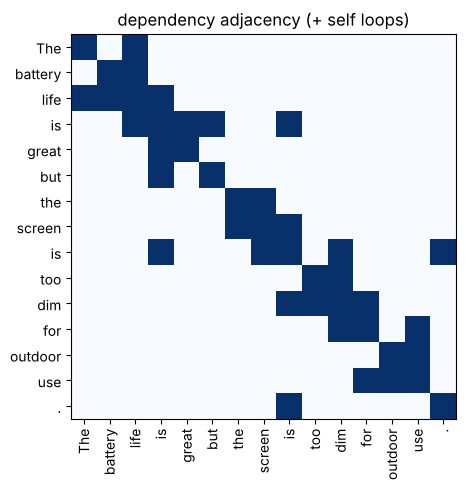

In [4]:
import spacy, matplotlib.pyplot as plt
from absa.graph import adjacency, tree_distances
nlp = spacy.load('en_core_web_lg')
s = 'The battery life is great but the screen is too dim for outdoor use.'
doc = nlp(s)
for t in doc: print(f'{t.i:2d} {t.text:10s} --{t.dep_:>6s}--> {t.head.i:2d} {t.head.text}')
heads = [t.head.i for t in doc]
A = adjacency(heads, 'dep')
asp = [1, 2]   # 'battery life'
print('\ntree distance from "battery life":', dict(zip([t.text for t in doc], tree_distances(heads, asp))))
fig, ax = plt.subplots(figsize=(5, 5)); ax.imshow(A, cmap='Blues')
ax.set_xticks(range(len(doc))); ax.set_xticklabels([t.text for t in doc], rotation=90)
ax.set_yticks(range(len(doc))); ax.set_yticklabels([t.text for t in doc]); ax.set_title('dependency adjacency (+ self loops)'); plt.show()

In the linear order, *great* and *dim* are both exactly 3 tokens away from *screen*, so a purely sequential model has no positional cue for which opinion belongs to it. In the tree, *dim* is 2 hops from *screen* and *great* is 3 hops away (through the `conj` edge), while from *battery life* *great* is 2 hops away and *dim* 3. The GNNs propagate information only along these edges, so the opinion word that is *syntactically* attached to an aspect dominates its representation.

**Models** (`src/absa/models.py`):
* **BiLSTM+Att**: same encoder/readout as the GNNs, no graph (ablation baseline)
* **GCN**: ASGCN-style. BiLSTM, then 2 GCN layers over the dependency graph (position-weighted), aspect mask, attention readout
* **GAT**: the GCN layers replaced by 4-head graph attention restricted to dependency neighbours
* **R-GAT**: GAT whose attention logits and messages also use the dependency *relation* label (nsubj, amod, ...)
* **RoBERTa**: fine-tuned sentence-pair transformer baseline `<s> sentence </s></s> aspect </s>`
* **RoBERTa+GCN / RoBERTa+R-GAT**: RoBERTa word states go through a dependency GNN; the classifier sees [CLS; aspect]

## 3. Main results

In [5]:
show_md('results/tables/main_results.md')

### Test accuracy (%), mean ± std over seeds

|                          | Rest14       | Lap14        | MAMS         | Yelp         | Amazon23 (distant)   |
|:-------------------------|:-------------|:-------------|:-------------|:-------------|:---------------------|
| BiLSTM+Att (no graph)    | 78.96 ± 0.05 | 70.59 ± 0.71 | 77.97 ± 0.23 | 84.35 ± 2.36 | 93.36 ± 1.01         |
| GCN (dep. tree)          | 79.08 ± 1.32 | 69.28 ± 2.28 | 78.44 ± 0.46 | 84.76 ± 1.18 | 94.09 ± 1.13         |
| GAT (dep. tree)          | 78.51 ± 0.72 | 68.76 ± 1.60 | 77.92 ± 1.01 | 83.40 ± 0.47 | 95.26 ± 0.41         |
| R-GAT (dep. tree + rel.) | 79.14 ± 0.68 | 70.48 ± 0.89 | 78.47 ± 0.58 | 84.49 ± 0.41 | 94.44 ± 1.06         |
| RoBERTa (fine-tuned)     | 84.02 ± 1.26 | 77.66 ± 0.78 | 83.46        | 81.02 ± 0.29 | 95.69                |
| RoBERTa+GCN              | 84.42 ± 0.06 | 78.68 ± 0.44 | nan          | 84.69 ± 3.75 | 96.27                |
| RoBERTa+R-GAT            | 84.11 ± 0.00 | 78.13 ± 0.33 | 83.23        | 83.67 ± 1.73 | 95.45                |

### Test macro-F1 (%), mean ± std over seeds

|                          | Rest14       | Lap14        | MAMS         | Yelp         | Amazon23 (distant)   |
|:-------------------------|:-------------|:-------------|:-------------|:-------------|:---------------------|
| BiLSTM+Att (no graph)    | 68.38 ± 0.37 | 64.48 ± 0.92 | 76.88 ± 0.26 | 61.05 ± 4.63 | 92.89 ± 0.99         |
| GCN (dep. tree)          | 69.99 ± 2.44 | 64.26 ± 2.64 | 77.39 ± 0.73 | 64.53 ± 7.68 | 93.58 ± 1.10         |
| GAT (dep. tree)          | 67.36 ± 1.74 | 62.28 ± 3.03 | 77.08 ± 1.07 | 61.98 ± 2.39 | 94.91 ± 0.44         |
| R-GAT (dep. tree + rel.) | 69.13 ± 0.41 | 64.78 ± 1.62 | 77.38 ± 0.67 | 63.87 ± 0.92 | 93.99 ± 1.15         |
| RoBERTa (fine-tuned)     | 74.69 ± 3.14 | 72.76 ± 1.51 | 83.08        | 51.92 ± 0.45 | 95.34                |
| RoBERTa+GCN              | 75.98 ± 0.04 | 74.20 ± 0.12 | nan          | 55.18 ± 3.28 | 96.09                |
| RoBERTa+R-GAT            | 75.57 ± 0.39 | 73.94 ± 1.07 | 82.83        | 57.64 ± 2.37 | 95.19                |

Seeds per cell:

| model       |   amazon23 |   lap14 |   mams |   rest14 |   yelp |
|:------------|-----------:|--------:|-------:|---------:|-------:|
| gat         |          3 |       3 |      3 |        3 |      3 |
| gcn         |          3 |       3 |      3 |        3 |      3 |
| lstm        |          3 |       3 |      3 |        3 |      3 |
| rgat        |          3 |       3 |      3 |        3 |      3 |
| roberta     |          1 |       2 |      1 |        2 |      2 |
| roberta-gat |          1 |       2 |      1 |        2 |      2 |
| roberta-gcn |          1 |       2 |    nan |        2 |      2 |


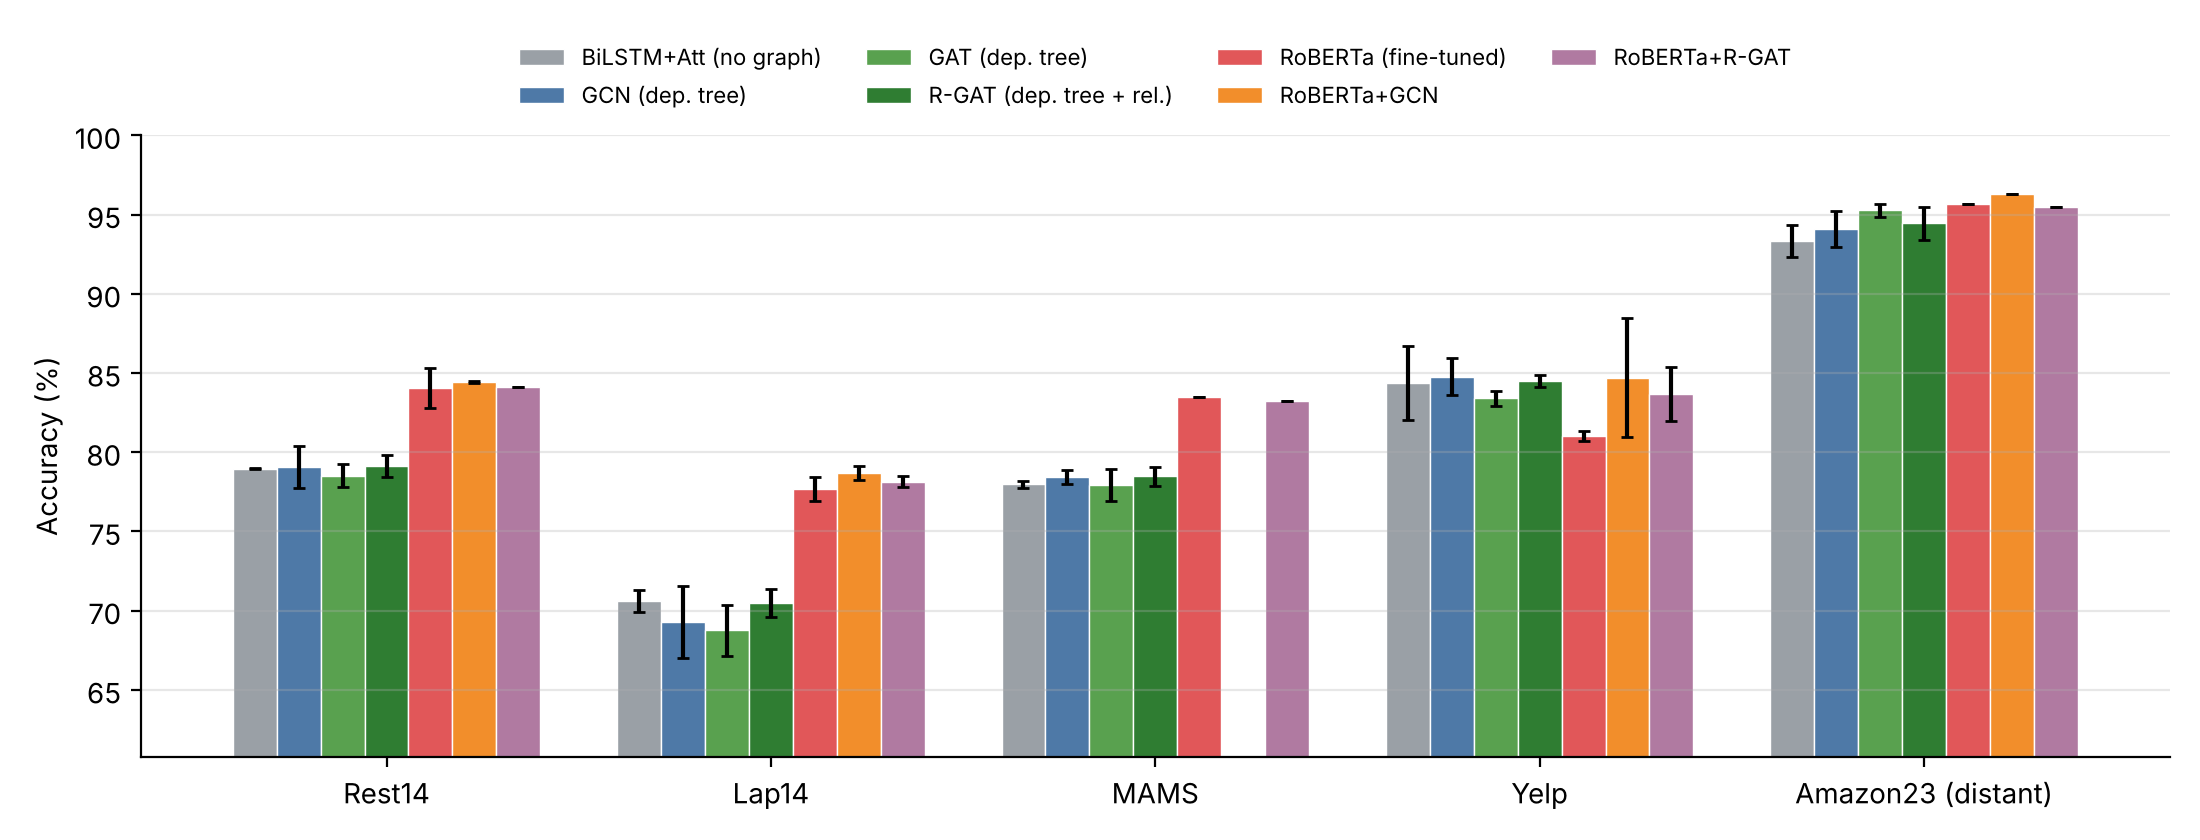

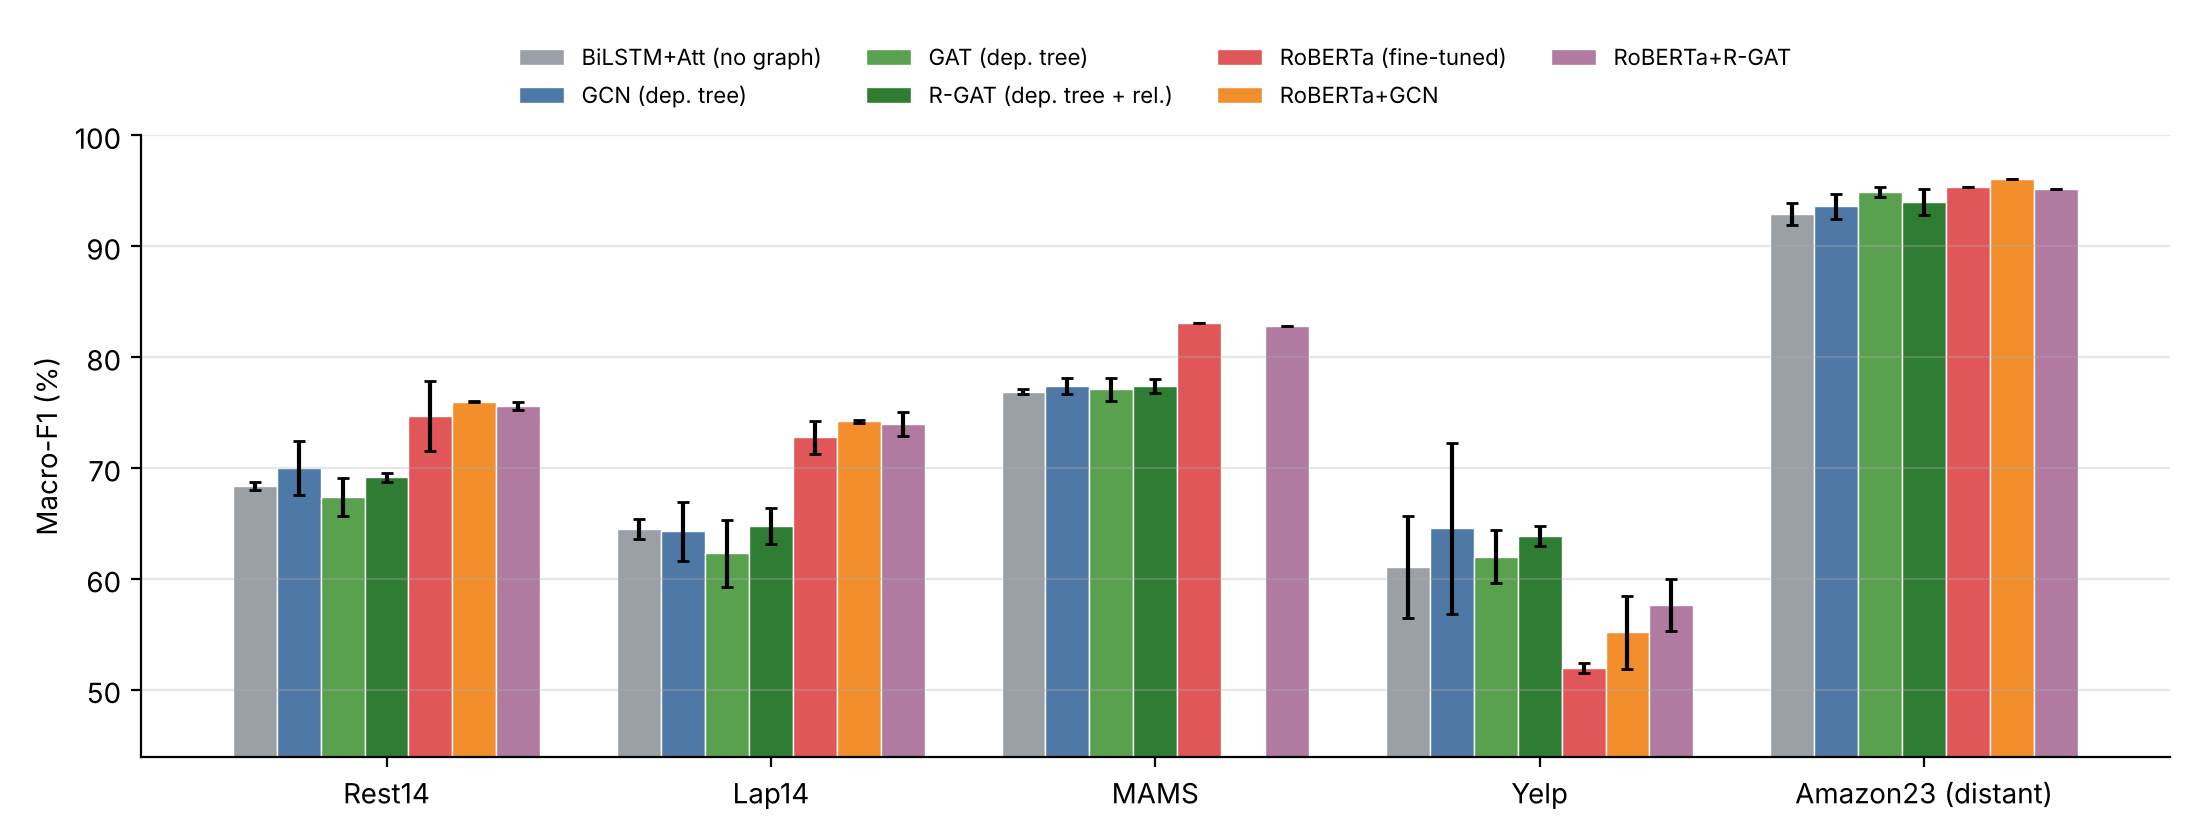

In [6]:
display(Image(f'{ROOT}/results/figures/main_acc.png')); display(Image(f'{ROOT}/results/figures/main_f1.png'))

### Significance (paired bootstrap over test examples, correctness averaged over seeds)

In [7]:
show_md('results/tables/significance.md')

| dataset                                         | A                        | B                        |   acc(A)-acc(B) |   p (A<=B) |
|:------------------------------------------------|:-------------------------|:-------------------------|----------------:|-----------:|
| Rest14                                          | GCN (dep. tree)          | BiLSTM+Att (no graph)    |            0.12 |     0.4384 |
| Rest14                                          | GAT (dep. tree)          | BiLSTM+Att (no graph)    |           -0.45 |     0.738  |
| Rest14                                          | R-GAT (dep. tree + rel.) | BiLSTM+Att (no graph)    |            0.18 |     0.4026 |
| Rest14                                          | R-GAT (dep. tree + rel.) | GCN (dep. tree)          |            0.06 |     0.4676 |
| Rest14                                          | GAT (dep. tree)          | GCN (dep. tree)          |           -0.57 |     0.8202 |
| Rest14                                          | RoBERTa (fine-tuned)     | R-GAT (dep. tree + rel.) |            4.88 |     0      |
| Rest14                                          | RoBERTa+R-GAT            | RoBERTa (fine-tuned)     |            0.09 |     0.4508 |
| Rest14                                          | RoBERTa+GCN              | RoBERTa (fine-tuned)     |            0.4  |     0.2724 |
| Lap14                                           | GCN (dep. tree)          | BiLSTM+Att (no graph)    |           -1.31 |     0.8582 |
| Lap14                                           | GAT (dep. tree)          | BiLSTM+Att (no graph)    |           -1.83 |     0.941  |
| Lap14                                           | R-GAT (dep. tree + rel.) | BiLSTM+Att (no graph)    |           -0.1  |     0.5324 |
| Lap14                                           | R-GAT (dep. tree + rel.) | GCN (dep. tree)          |            1.2  |     0.0782 |
| Lap14                                           | GAT (dep. tree)          | GCN (dep. tree)          |           -0.52 |     0.7146 |
| Lap14                                           | RoBERTa (fine-tuned)     | R-GAT (dep. tree + rel.) |            7.18 |     0      |
| Lap14                                           | RoBERTa+R-GAT            | RoBERTa (fine-tuned)     |            0.47 |     0.3596 |
| Lap14                                           | RoBERTa+GCN              | RoBERTa (fine-tuned)     |            1.02 |     0.184  |
| MAMS                                            | GCN (dep. tree)          | BiLSTM+Att (no graph)    |            0.47 |     0.2608 |
| MAMS                                            | GAT (dep. tree)          | BiLSTM+Att (no graph)    |           -0.05 |     0.5406 |
| MAMS                                            | R-GAT (dep. tree + rel.) | BiLSTM+Att (no graph)    |            0.5  |     0.2516 |
| MAMS                                            | R-GAT (dep. tree + rel.) | GCN (dep. tree)          |            0.02 |     0.495  |
| MAMS                                            | GAT (dep. tree)          | GCN (dep. tree)          |           -0.52 |     0.8438 |
| MAMS                                            | RoBERTa (fine-tuned)     | R-GAT (dep. tree + rel.) |            4.99 |     0      |
| MAMS                                            | RoBERTa+R-GAT            | RoBERTa (fine-tuned)     |           -0.22 |     0.6364 |
| Yelp                                            | GCN (dep. tree)          | BiLSTM+Att (no graph)    |            0.41 |     0.4144 |
| Yelp                                            | GAT (dep. tree)          | BiLSTM+Att (no graph)    |           -0.95 |     0.7368 |
| Yelp                                            | R-GAT (dep. tree + rel.) | BiLSTM+Att (no graph)    |            0.14 |     0.4652 |
| Yelp                                            | R-GAT (dep. tree + rel.) | GCN (dep. tree)          |           -0.27 |     0.6066 |
| Yelp                                            | GAT (dep. tree)          | GCN (dep. tree)          |           -1.36 |     0.9038 |
| Yelp                                            | RoBERTa (fine-tuned)     | R-GAT (dep. tree + rel.) |           -3.47 |     0.9766 |
| Yelp                                            | RoBERTa+R-GAT            | RoBERTa (fine-tuned)     |            2.65 |     0.0266 |
| Yelp                                            | RoBERTa+GCN              | RoBERTa (fine-tuned)     |            3.67 |     0.0002 |
| Amazon23 (distant)                              | GCN (dep. tree)          | BiLSTM+Att (no graph)    |            0.74 |     0.0574 |
| Amazon23 (distant)                              | GAT (dep. tree)          | BiLSTM+Att (no graph)    |            1.9  |     0      |
| Amazon23 (distant)                              | R-GAT (dep. tree + rel.) | BiLSTM+Att (no graph)    |            1.09 |     0.0158 |
| Amazon23 (distant)                              | R-GAT (dep. tree + rel.) | GCN (dep. tree)          |            0.35 |     0.1786 |
| Amazon23 (distant)                              | GAT (dep. tree)          | GCN (dep. tree)          |            1.17 |     0.0022 |
| Amazon23 (distant)                              | RoBERTa (fine-tuned)     | R-GAT (dep. tree + rel.) |            1.24 |     0.0382 |
| Amazon23 (distant)                              | RoBERTa+R-GAT            | RoBERTa (fine-tuned)     |           -0.23 |     0.7206 |
| Amazon23 (distant)                              | RoBERTa+GCN              | RoBERTa (fine-tuned)     |            0.58 |     0.1324 |
| Amazon23 (gold) (trained on Amazon23 (distant)) | GCN (dep. tree)          | BiLSTM+Att (no graph)    |            1.63 |     0.125  |
| Amazon23 (gold) (trained on Amazon23 (distant)) | GAT (dep. tree)          | BiLSTM+Att (no graph)    |           -0.3  |     0.618  |
| Amazon23 (gold) (trained on Amazon23 (distant)) | R-GAT (dep. tree + rel.) | BiLSTM+Att (no graph)    |            0.3  |     0.4258 |
| Amazon23 (gold) (trained on Amazon23 (distant)) | R-GAT (dep. tree + rel.) | GCN (dep. tree)          |           -1.33 |     0.8858 |
| Amazon23 (gold) (trained on Amazon23 (distant)) | GAT (dep. tree)          | GCN (dep. tree)          |           -1.93 |     0.9708 |
| Amazon23 (gold) (trained on Amazon23 (distant)) | RoBERTa (fine-tuned)     | R-GAT (dep. tree + rel.) |            1.33 |     0.2566 |
| Amazon23 (gold) (trained on Amazon23 (distant)) | RoBERTa+R-GAT            | RoBERTa (fine-tuned)     |           -0.44 |     0.7582 |
| Amazon23 (gold) (trained on Amazon23 (distant)) | RoBERTa+GCN              | RoBERTa (fine-tuned)     |            3.11 |     0.0004 |
| Amazon23 (gold) (trained on Lap14)              | GCN (dep. tree)          | BiLSTM+Att (no graph)    |           -3.26 |     0.9322 |
| Amazon23 (gold) (trained on Lap14)              | GAT (dep. tree)          | BiLSTM+Att (no graph)    |           -7.41 |     1      |
| Amazon23 (gold) (trained on Lap14)              | R-GAT (dep. tree + rel.) | BiLSTM+Att (no graph)    |           -5.19 |     0.9944 |
| Amazon23 (gold) (trained on Lap14)              | R-GAT (dep. tree + rel.) | GCN (dep. tree)          |           -1.93 |     0.8912 |
| Amazon23 (gold) (trained on Lap14)              | GAT (dep. tree)          | GCN (dep. tree)          |           -4.15 |     0.9988 |
| Amazon23 (gold) (trained on Lap14)              | RoBERTa (fine-tuned)     | R-GAT (dep. tree + rel.) |           13.04 |     0      |
| Amazon23 (gold) (trained on Lap14)              | RoBERTa+R-GAT            | RoBERTa (fine-tuned)     |            4    |     0.0748 |
| Amazon23 (gold) (trained on Lap14)              | RoBERTa+GCN              | RoBERTa (fine-tuned)     |            5.11 |     0.0194 |

## 4. Cross-domain transfer

In [8]:
show_md('results/tables/cross_domain.md')

### Transfer accuracy (%)

|                          | Amazon23 (distant) -> Amazon23 (gold)   | Amazon23 (distant) -> Lap14   | Lap14 -> Amazon23 (distant)   | Lap14 -> Amazon23 (gold)   | Rest14 -> Yelp   | Yelp -> Rest14   |
|:-------------------------|:----------------------------------------|:------------------------------|:------------------------------|:---------------------------|:-----------------|:-----------------|
| BiLSTM+Att (no graph)    | 49.48 ± 1.36                            | 64.94 ± 0.63                  | 66.74 ± 2.66                  | 51.26 ± 4.03               | 84.90 ± 2.16     | 70.30 ± 1.09     |
| GCN (dep. tree)          | 51.11 ± 2.35                            | 66.04 ± 1.86                  | 70.01 ± 2.51                  | 48.00 ± 3.36               | 84.35 ± 1.93     | 72.74 ± 0.83     |
| GAT (dep. tree)          | 49.19 ± 1.36                            | 65.31 ± 1.37                  | 69.85 ± 1.59                  | 43.85 ± 6.13               | 83.54 ± 0.24     | 73.01 ± 1.34     |
| R-GAT (dep. tree + rel.) | 49.78 ± 0.44                            | 65.78 ± 0.74                  | 70.59 ± 1.31                  | 46.07 ± 2.96               | 85.58 ± 1.65     | 72.44 ± 0.99     |
| RoBERTa (fine-tuned)     | 51.11                                   | 68.18                         | 79.55 ± 1.24                  | 59.11 ± 0.63               | 87.96 ± 0.87     | 75.31 ± 0.06     |
| RoBERTa+GCN              | 54.22                                   | 68.34                         | 75.70 ± 1.40                  | 64.22 ± 2.83               | 86.94 ± 0.58     | 75.49 ± 1.83     |
| RoBERTa+R-GAT            | 50.67                                   | 69.12                         | 72.90 ± 1.57                  | 63.11 ± 0.63               | 89.18 ± 0.87     | 74.33 ± 0.82     |

### Transfer macro-F1 (%)

|                          | Amazon23 (distant) -> Amazon23 (gold)   | Amazon23 (distant) -> Lap14   | Lap14 -> Amazon23 (distant)   | Lap14 -> Amazon23 (gold)   | Rest14 -> Yelp   | Yelp -> Rest14   |
|:-------------------------|:----------------------------------------|:------------------------------|:------------------------------|:---------------------------|:-----------------|:-----------------|
| BiLSTM+Att (no graph)    | 47.04 ± 1.11                            | 59.09 ± 0.69                  | 63.28 ± 1.46                  | 50.36 ± 3.17               | 65.41 ± 5.02     | 46.96 ± 2.01     |
| GCN (dep. tree)          | 48.22 ± 1.94                            | 60.60 ± 2.05                  | 65.51 ± 3.59                  | 48.08 ± 1.74               | 64.63 ± 4.97     | 51.45 ± 1.48     |
| GAT (dep. tree)          | 46.82 ± 1.69                            | 59.79 ± 1.19                  | 64.08 ± 4.15                  | 43.68 ± 6.39               | 62.23 ± 1.58     | 50.68 ± 1.51     |
| R-GAT (dep. tree + rel.) | 47.18 ± 0.41                            | 59.93 ± 1.38                  | 65.50 ± 1.86                  | 46.19 ± 2.19               | 67.23 ± 5.07     | 51.00 ± 1.22     |
| RoBERTa (fine-tuned)     | 48.56                                   | 62.05                         | 75.64 ± 1.46                  | 57.32 ± 0.31               | 66.74 ± 4.26     | 51.77 ± 0.12     |
| RoBERTa+GCN              | 51.99                                   | 62.39                         | 71.97 ± 1.61                  | 63.50 ± 2.52               | 64.99 ± 0.20     | 51.62 ± 2.11     |
| RoBERTa+R-GAT            | 47.42                                   | 63.76                         | 69.69 ± 1.20                  | 61.86 ± 0.33               | 65.99 ± 0.12     | 52.22 ± 1.05     |



## 5. Ablations: does the *syntax* matter, or just having a graph?

### Graph structure ablation - acc (%)

| graph         | gat / lap14   | gat / rest14   | gcn / lap14   | gcn / rest14   |
|:--------------|:--------------|:---------------|:--------------|:---------------|
| dep           | 68.76 ± 1.60  | 78.51 ± 0.72   | 69.28 ± 2.28  | 79.08 ± 1.32   |
| seq           | 70.53 ± 0.57  | 79.88 ± 0.88   | 69.59 ± 2.04  | 80.33 ± 1.50   |
| random        | 67.97 ± 2.22  | 76.61 ± 0.50   | 68.50 ± 0.98  | 76.55 ± 1.75   |
| full          | 68.65 ± 1.39  | 78.54 ± 0.81   | 68.55 ± 0.72  | 77.92 ± 2.15   |
| none (BiLSTM) | 70.59 ± 0.71  | 78.96 ± 0.05   | 70.59 ± 0.71  | 78.96 ± 0.05   |

### Graph structure ablation - f1 (%)

| graph         | gat / lap14   | gat / rest14   | gcn / lap14   | gcn / rest14   |
|:--------------|:--------------|:---------------|:--------------|:---------------|
| dep           | 62.28 ± 3.03  | 67.36 ± 1.74   | 64.26 ± 2.64  | 69.99 ± 2.44   |
| seq           | 65.13 ± 0.86  | 69.45 ± 1.95   | 63.66 ± 3.83  | 70.90 ± 3.09   |
| random        | 62.28 ± 2.47  | 64.75 ± 2.67   | 62.72 ± 1.77  | 64.75 ± 2.39   |
| full          | 62.36 ± 1.44  | 67.45 ± 1.06   | 62.25 ± 0.95  | 67.69 ± 3.79   |
| none (BiLSTM) | 64.48 ± 0.92  | 68.38 ± 0.37   | 64.48 ± 0.92  | 68.38 ± 0.37   |

### Number of graph layers - acc (%)

|   layers | gat / lap14   | gat / rest14   | gcn / lap14   | gcn / rest14   |
|---------:|:--------------|:---------------|:--------------|:---------------|
|        1 | nan           | nan            | 69.28 ± 0.31  | 79.40 ± 0.87   |
|        2 | 68.76 ± 1.60  | 78.51 ± 0.72   | 69.28 ± 2.28  | 79.08 ± 1.32   |
|        3 | nan           | nan            | 68.76 ± 2.37  | 78.78 ± 0.72   |
|        4 | nan           | nan            | 69.33 ± 1.13  | 78.12 ± 1.72   |

### Number of graph layers - f1 (%)

|   layers | gat / lap14   | gat / rest14   | gcn / lap14   | gcn / rest14   |
|---------:|:--------------|:---------------|:--------------|:---------------|
|        1 | nan           | nan            | 63.70 ± 1.36  | 68.98 ± 1.42   |
|        2 | 62.28 ± 3.03  | 67.36 ± 1.74   | 64.26 ± 2.64  | 69.99 ± 2.44   |
|        3 | nan           | nan            | 62.27 ± 2.99  | 70.21 ± 0.71   |
|        4 | nan           | nan            | 63.57 ± 2.62  | 67.15 ± 3.27   |



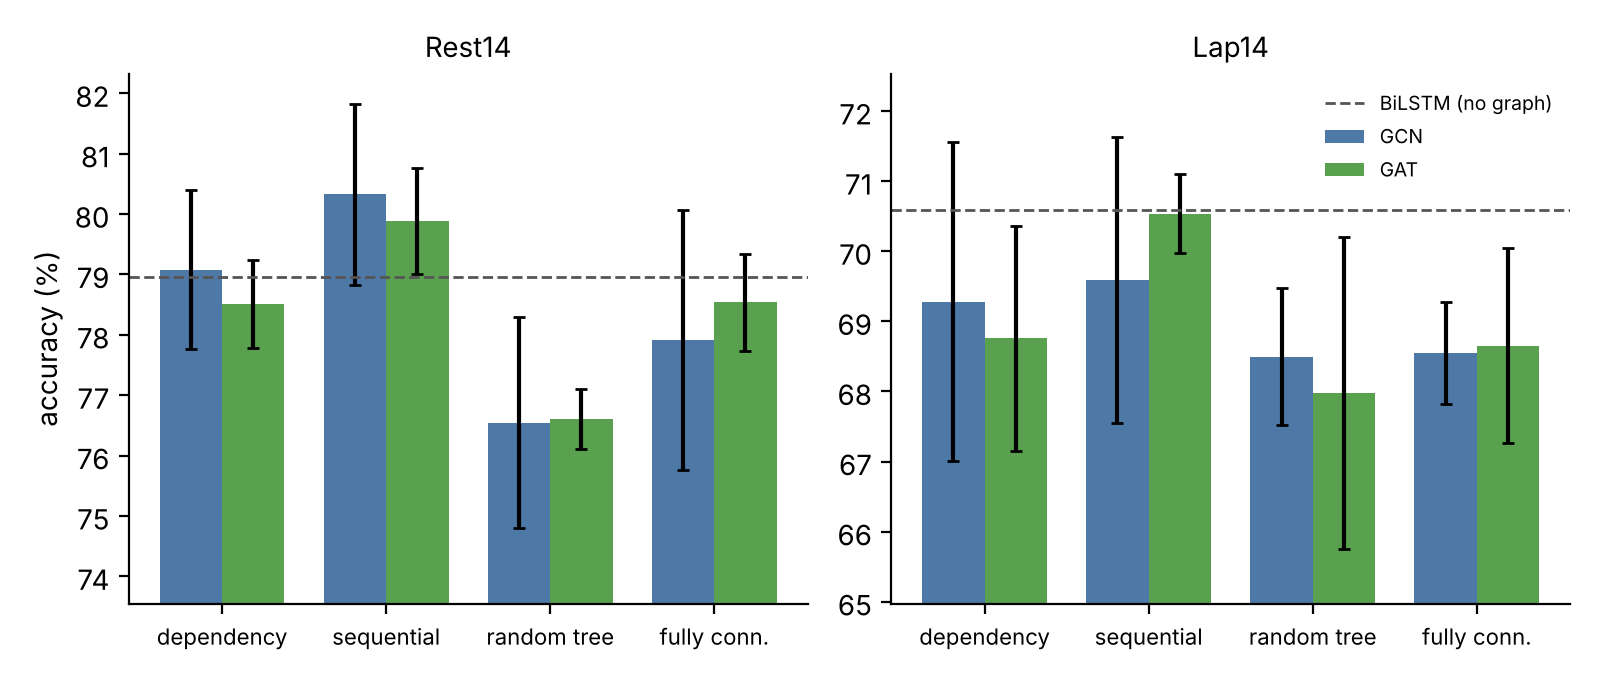

In [9]:
show_md('results/tables/ablation.md')
if os.path.exists(f'{ROOT}/results/figures/ablation_graph.png'): display(Image(f'{ROOT}/results/figures/ablation_graph.png'))

## 6. Fine-grained analysis

In [10]:
show_md('results/tables/fine_grained.md')

### Rest14: accuracy (%) by subgroup (seed-averaged)

| group                                             |    n |   BiLSTM+Att (no graph) |   GCN (dep. tree) |   GAT (dep. tree) |   R-GAT (dep. tree + rel.) |   RoBERTa (fine-tuned) |   RoBERTa+GCN |   RoBERTa+R-GAT |
|:--------------------------------------------------|-----:|------------------------:|------------------:|------------------:|---------------------------:|-----------------------:|--------------:|----------------:|
| all                                               | 1120 |                    79   |              79.1 |              78.5 |                       79.1 |                   84   |          84.4 |            84.1 |
| single-aspect sentence                            |  305 |                    76.4 |              77.2 |              77.7 |                       78.9 |                   85.4 |          84.8 |            85.1 |
| multi-aspect sentence                             |  815 |                    79.9 |              79.8 |              78.8 |                       79.2 |                   83.5 |          84.3 |            83.7 |
| mixed-polarity sentence                           |  218 |                    63.6 |              60.6 |              58.9 |                       61.5 |                   67.2 |          68.8 |            69.7 |
| contrast marker (but/however/...)                 |  156 |                    82.7 |              75.9 |              75.4 |                       78.6 |                   85.6 |          85.6 |            87.8 |
| length <= 15                                      |  493 |                    80.5 |              81.5 |              80.9 |                       80.6 |                   85.7 |          85.9 |            86   |
| length 16-30                                      |  500 |                    77.1 |              77.3 |              76.7 |                       78   |                   81.8 |          83.1 |            82.1 |
| length > 30                                       |  127 |                    80.6 |              76.6 |              76.4 |                       78   |                   86.2 |          83.9 |            84.6 |
| opinion word: tree dist 1                         |  253 |                    88.3 |              89.3 |              89.9 |                       88.4 |                   90.7 |          92.9 |            91.3 |
| opinion word: tree dist 2                         |  300 |                    88.7 |              88.8 |              89   |                       89.8 |                   92.3 |          92.8 |            93   |
| opinion word: tree dist >= 3                      |  347 |                    77.8 |              75.1 |              75.9 |                       76.5 |                   81.7 |          81.3 |            80.5 |
| linear dist >= 4                                  |  359 |                    76.9 |              75.3 |              76.2 |                       77.8 |                   82   |          82.6 |            82   |
| linear >> tree (lin - tree >= 3)                  |  215 |                    76   |              73   |              75   |                       76   |                   80   |          79.8 |            78.8 |
| distractor (lin-closest opinion not tree-closest) |   76 |                    79.8 |              72.4 |              74.1 |                       73.7 |                   82.9 |          80.3 |            80.9 |

### Lap14: accuracy (%) by subgroup (seed-averaged)

| group                                             |   n |   BiLSTM+Att (no graph) |   GCN (dep. tree) |   GAT (dep. tree) |   R-GAT (dep. tree + rel.) |   RoBERTa (fine-tuned) |   RoBERTa+GCN |   RoBERTa+R-GAT |
|:--------------------------------------------------|----:|------------------------:|------------------:|------------------:|---------------------------:|-----------------------:|--------------:|----------------:|
| all                                               | 638 |                    70.6 |              69.3 |              68.8 |                       70.5 |                   77.7 |          78.7 |            78.1 |
| single-aspect sentence                            | 278 |                    67.9 |              68.3 |              67.7 |                       68.3 |                   80.6 |          78.1 |            77.7 |
| multi-aspect sentence                             | 360 |                    72.7 |              70   |              69.5 |                       72.1 |                   75.4 |          79.2 |            78.5 |
| mixed-polarity sentence                           |  97 |                    58.4 |              51.9 |              46   |                       48.5 |                   44.3 |          59.8 |            61.9 |
| contrast marker (but/however/...)                 |  70 |                    55.2 |              53.3 |              49   |                       50.5 |                   60   |          59.3 |            62.9 |
| length <= 15                                      | 308 |                    75.4 |              73.6 |              75.9 |                       76.8 |                   85.7 |          85.9 |            84.3 |
| length 16-30                                      | 273 |                    66.5 |              66.1 |              63.4 |                       65.3 |                   70.7 |          71.6 |            72   |
| length > 30                                       |  57 |                    63.7 |              61.4 |              56.1 |                       60.8 |                   67.5 |          73.7 |            74.6 |
| opinion word: tree dist 1                         | 126 |                    83.6 |              81.5 |              81.2 |                       84.9 |                   84.5 |          85.3 |            85.3 |
| opinion word: tree dist 2                         | 133 |                    78.9 |              78.7 |              78.7 |                       81   |                   86.5 |          87.2 |            85.7 |
| opinion word: tree dist >= 3                      | 152 |                    61.8 |              61.4 |              59   |                       61   |                   71.4 |          70.4 |            72.4 |
| linear dist >= 4                                  | 169 |                    63.3 |              63.7 |              62.5 |                       65.7 |                   74   |          72.5 |            75.1 |
| linear >> tree (lin - tree >= 3)                  | 108 |                    66.4 |              64.2 |              61.7 |                       66.4 |                   74.1 |          72.7 |            74.5 |
| distractor (lin-closest opinion not tree-closest) |  28 |                    73.8 |              70.2 |              63.1 |                       64.3 |                   66.1 |          73.2 |            73.2 |

### MAMS: accuracy (%) by subgroup (seed-averaged)

| group                                             |    n |   BiLSTM+Att (no graph) |   GCN (dep. tree) |   GAT (dep. tree) |   R-GAT (dep. tree + rel.) |   RoBERTa (fine-tuned) |   RoBERTa+GCN |   RoBERTa+R-GAT |
|:--------------------------------------------------|-----:|------------------------:|------------------:|------------------:|---------------------------:|-----------------------:|--------------:|----------------:|
| all                                               | 1336 |                    78   |              78.4 |              77.9 |                       78.5 |                   83.5 |           nan |            83.2 |
| single-aspect sentence                            |    2 |                   100   |             100   |             100   |                      100   |                  100   |           nan |           100   |
| multi-aspect sentence                             | 1334 |                    77.9 |              78.4 |              77.9 |                       78.4 |                   83.4 |           nan |            83.2 |
| mixed-polarity sentence                           | 1334 |                    77.9 |              78.4 |              77.9 |                       78.4 |                   83.4 |           nan |            83.2 |
| contrast marker (but/however/...)                 |  347 |                    78.4 |              77.9 |              77   |                       78.8 |                   83.3 |           nan |            83.6 |
| length <= 15                                      |  127 |                    78.2 |              81.4 |              81.4 |                       80.3 |                   82.7 |           nan |            85   |
| length 16-30                                      |  731 |                    78   |              78.6 |              77.7 |                       78.3 |                   85.5 |           nan |            85.4 |
| length > 30                                       |  478 |                    77.8 |              77.5 |              77.3 |                       78.2 |                   80.5 |           nan |            79.5 |
| opinion word: tree dist 1                         |  165 |                    74.9 |              79.2 |              76.2 |                       76   |                   85.5 |           nan |            87.9 |
| opinion word: tree dist 2                         |  235 |                    74.5 |              77.3 |              76   |                       77.3 |                   83.4 |           nan |            82.1 |
| opinion word: tree dist >= 3                      |  597 |                    77.4 |              77.2 |              77   |                       77.1 |                   80.9 |           nan |            81.1 |
| linear dist >= 4                                  |  627 |                    75.6 |              76.5 |              75.5 |                       75.9 |                   80.7 |           nan |            80.9 |
| linear >> tree (lin - tree >= 3)                  |  441 |                    74.7 |              77.5 |              76.3 |                       76.3 |                   80   |           nan |            80.7 |
| distractor (lin-closest opinion not tree-closest) |   97 |                    78.4 |              77.7 |              79.7 |                       80.8 |                   87.6 |           nan |            86.6 |

### Yelp: accuracy (%) by subgroup (seed-averaged)

| group                                             |   n |   BiLSTM+Att (no graph) |   GCN (dep. tree) |   GAT (dep. tree) |   R-GAT (dep. tree + rel.) |   RoBERTa (fine-tuned) |   RoBERTa+GCN |   RoBERTa+R-GAT |
|:--------------------------------------------------|----:|------------------------:|------------------:|------------------:|---------------------------:|-----------------------:|--------------:|----------------:|
| all                                               | 245 |                    84.4 |              84.8 |              83.4 |                       84.5 |                   81   |          84.7 |            83.7 |
| single-aspect sentence                            | 136 |                    81.1 |              83.3 |              80.9 |                       81.6 |                   78.7 |          82.7 |            80.5 |
| multi-aspect sentence                             | 109 |                    88.4 |              86.5 |              86.5 |                       88.1 |                   83.9 |          87.2 |            87.6 |
| mixed-polarity sentence                           |  22 |                    77.3 |              62.1 |              62.1 |                       60.6 |                   54.5 |          61.4 |            63.6 |
| contrast marker (but/however/...)                 |  64 |                    74   |              72.9 |              69.8 |                       70.3 |                   57   |          68.8 |            67.2 |
| length <= 15                                      | 116 |                    88.2 |              90.5 |              89.1 |                       89.7 |                   84.5 |          85.8 |            84.5 |
| length 16-30                                      | 110 |                    80   |              79.1 |              78.5 |                       80   |                   76.4 |          84.1 |            82.3 |
| length > 30                                       |  19 |                    86   |              82.5 |              77.2 |                       78.9 |                   86.8 |          81.6 |            86.8 |
| opinion word: tree dist 1                         |  58 |                    93.7 |              89.7 |              90.8 |                       90.2 |                   92.2 |          94.8 |            94.8 |
| opinion word: tree dist 2                         |  89 |                    88.4 |              91   |              90.6 |                       90.3 |                   80.9 |          86.5 |            83.7 |
| opinion word: tree dist >= 3                      |  71 |                    75.1 |              74.6 |              72.3 |                       75.1 |                   77.5 |          79.6 |            80.3 |
| linear dist >= 4                                  |  79 |                    71.7 |              73.4 |              70.5 |                       70.9 |                   75.9 |          77.2 |            75.9 |
| linear >> tree (lin - tree >= 3)                  |  48 |                    70.1 |              71.5 |              67.4 |                       71.5 |                   75   |          76   |            77.1 |
| distractor (lin-closest opinion not tree-closest) |  17 |                    80.4 |              82.4 |              78.4 |                       78.4 |                   85.3 |          94.1 |            94.1 |

### Amazon23 (distant): accuracy (%) by subgroup (seed-averaged)

| group                                             |   n |   BiLSTM+Att (no graph) |   GCN (dep. tree) |   GAT (dep. tree) |   R-GAT (dep. tree + rel.) |   RoBERTa (fine-tuned) |   RoBERTa+GCN |   RoBERTa+R-GAT |
|:--------------------------------------------------|----:|------------------------:|------------------:|------------------:|---------------------------:|-----------------------:|--------------:|----------------:|
| all                                               | 858 |                    93.4 |              94.1 |              95.3 |                       94.4 |                   95.7 |          96.3 |            95.5 |
| single-aspect sentence                            | 610 |                    94   |              94.8 |              95.4 |                       95   |                   95.6 |          95.7 |            95.2 |
| multi-aspect sentence                             | 248 |                    91.8 |              92.3 |              94.9 |                       93.1 |                   96   |          97.6 |            96   |
| mixed-polarity sentence                           |   0 |                   nan   |             nan   |             nan   |                      nan   |                  nan   |         nan   |           nan   |
| contrast marker (but/however/...)                 |   0 |                   nan   |             nan   |             nan   |                      nan   |                  nan   |         nan   |           nan   |
| length <= 15                                      | 390 |                    96.4 |              96.9 |              97.5 |                       96.8 |                   97.9 |          97.4 |            97.7 |
| length 16-30                                      | 366 |                    90.4 |              91.7 |              93.4 |                       92.2 |                   93.7 |          95.4 |            93.7 |
| length > 30                                       | 102 |                    92.2 |              91.8 |              93.5 |                       93.5 |                   94.1 |          95.1 |            93.1 |
| opinion word: tree dist 1                         | 183 |                    94.7 |              95.4 |              96.2 |                       94.4 |                   96.7 |          96.7 |            97.3 |
| opinion word: tree dist 2                         | 167 |                    95.8 |              95.8 |              96.6 |                       97.2 |                   97.6 |          98.2 |            98.2 |
| opinion word: tree dist >= 3                      | 315 |                    92.1 |              93.8 |              94.8 |                       94.6 |                   96.2 |          96.2 |            95.2 |
| linear dist >= 4                                  | 323 |                    92   |              93.2 |              94.4 |                       93.9 |                   95.4 |          96   |            94.7 |
| linear >> tree (lin - tree >= 3)                  | 192 |                    91   |              91.1 |              93.8 |                       92.2 |                   95.3 |          96.4 |            94.3 |
| distractor (lin-closest opinion not tree-closest) |  65 |                    91.3 |              91.8 |              92.8 |                       91.8 |                   92.3 |          95.4 |            95.4 |

### Amazon23 (gold) (trained on Amazon23 (distant)): accuracy (%) by subgroup (seed-averaged)

| group                                             |   n |   BiLSTM+Att (no graph) |   GCN (dep. tree) |   GAT (dep. tree) |   R-GAT (dep. tree + rel.) |   RoBERTa (fine-tuned) |   RoBERTa+GCN |   RoBERTa+R-GAT |
|:--------------------------------------------------|----:|------------------------:|------------------:|------------------:|---------------------------:|-----------------------:|--------------:|----------------:|
| all                                               | 225 |                    49.5 |              51.1 |              49.2 |                       49.8 |                   51.1 |          54.2 |            50.7 |
| single-aspect sentence                            |  82 |                    58.1 |              63   |              59.8 |                       57.7 |                   62.2 |          67.1 |            62.2 |
| multi-aspect sentence                             | 143 |                    44.5 |              44.3 |              43.1 |                       45.2 |                   44.8 |          46.9 |            44.1 |
| mixed-polarity sentence                           |  93 |                    46.2 |              45.9 |              45.2 |                       47   |                   46.2 |          47.3 |            45.2 |
| contrast marker (but/however/...)                 | 141 |                    42.8 |              43.3 |              42.1 |                       43.7 |                   44.7 |          47.5 |            44   |
| length <= 15                                      |  48 |                    61.8 |              63.2 |              61.8 |                       62.5 |                   60.4 |          68.8 |            60.4 |
| length 16-30                                      | 126 |                    47.6 |              49.5 |              47.1 |                       47.9 |                   51.6 |          53.2 |            51.6 |
| length > 30                                       |  51 |                    42.5 |              43.8 |              42.5 |                       42.5 |                   41.2 |          43.1 |            39.2 |
| opinion word: tree dist 1                         |  26 |                    73.1 |              65.4 |              69.2 |                       70.5 |                   73.1 |          73.1 |            69.2 |
| opinion word: tree dist 2                         |  27 |                    54.3 |              54.3 |              54.3 |                       53.1 |                   59.3 |          59.3 |            63   |
| opinion word: tree dist >= 3                      |  96 |                    42.7 |              44.8 |              43.1 |                       42.7 |                   43.8 |          44.8 |            43.8 |
| linear dist >= 4                                  | 100 |                    43   |              44   |              43.7 |                       43.3 |                   45   |          46   |            44   |
| linear >> tree (lin - tree >= 3)                  |  72 |                    42.6 |              42.6 |              42.6 |                       43.5 |                   44.4 |          45.8 |            43.1 |
| distractor (lin-closest opinion not tree-closest) |   8 |                    62.5 |              66.7 |              62.5 |                       62.5 |                   62.5 |          62.5 |            62.5 |

### Amazon23 (gold) (trained on Lap14): accuracy (%) by subgroup (seed-averaged)

| group                                             |   n |   BiLSTM+Att (no graph) |   GCN (dep. tree) |   GAT (dep. tree) |   R-GAT (dep. tree + rel.) |   RoBERTa (fine-tuned) |   RoBERTa+GCN |   RoBERTa+R-GAT |
|:--------------------------------------------------|----:|------------------------:|------------------:|------------------:|---------------------------:|-----------------------:|--------------:|----------------:|
| all                                               | 225 |                    51.3 |              48   |              43.9 |                       46.1 |                   59.1 |          64.2 |            63.1 |
| single-aspect sentence                            |  82 |                    57.3 |              57.7 |              52.4 |                       54.5 |                   67.1 |          68.9 |            66.5 |
| multi-aspect sentence                             | 143 |                    47.8 |              42.4 |              38.9 |                       41.3 |                   54.5 |          61.5 |            61.2 |
| mixed-polarity sentence                           |  93 |                    49.5 |              45.2 |              44.4 |                       42.7 |                   46.8 |          59.1 |            62.4 |
| contrast marker (but/however/...)                 | 141 |                    47   |              41.6 |              38.3 |                       40   |                   49.6 |          59.6 |            59.6 |
| length <= 15                                      |  48 |                    60.4 |              52.8 |              48.6 |                       54.2 |                   62.5 |          62.5 |            60.4 |
| length 16-30                                      | 126 |                    46   |              46.6 |              43.1 |                       43.4 |                   63.1 |          67.5 |            64.3 |
| length > 30                                       |  51 |                    55.6 |              47.1 |              41.2 |                       45.1 |                   46.1 |          57.8 |            62.7 |
| opinion word: tree dist 1                         |  26 |                    69.2 |              67.9 |              69.2 |                       65.4 |                   67.3 |          75   |            78.8 |
| opinion word: tree dist 2                         |  27 |                    53.1 |              50.6 |              48.1 |                       51.9 |                   70.4 |          70.4 |            72.2 |
| opinion word: tree dist >= 3                      |  96 |                    54.9 |              48.6 |              43.1 |                       45.5 |                   54.2 |          62   |            64.1 |
| linear dist >= 4                                  | 100 |                    52.3 |              47   |              41.7 |                       43   |                   53   |          60   |            62   |
| linear >> tree (lin - tree >= 3)                  |  72 |                    51.9 |              47.7 |              41.7 |                       43.1 |                   51.4 |          56.2 |            58.3 |
| distractor (lin-closest opinion not tree-closest) |   8 |                    70.8 |              58.3 |              62.5 |                       66.7 |                   56.2 |          75   |            62.5 |



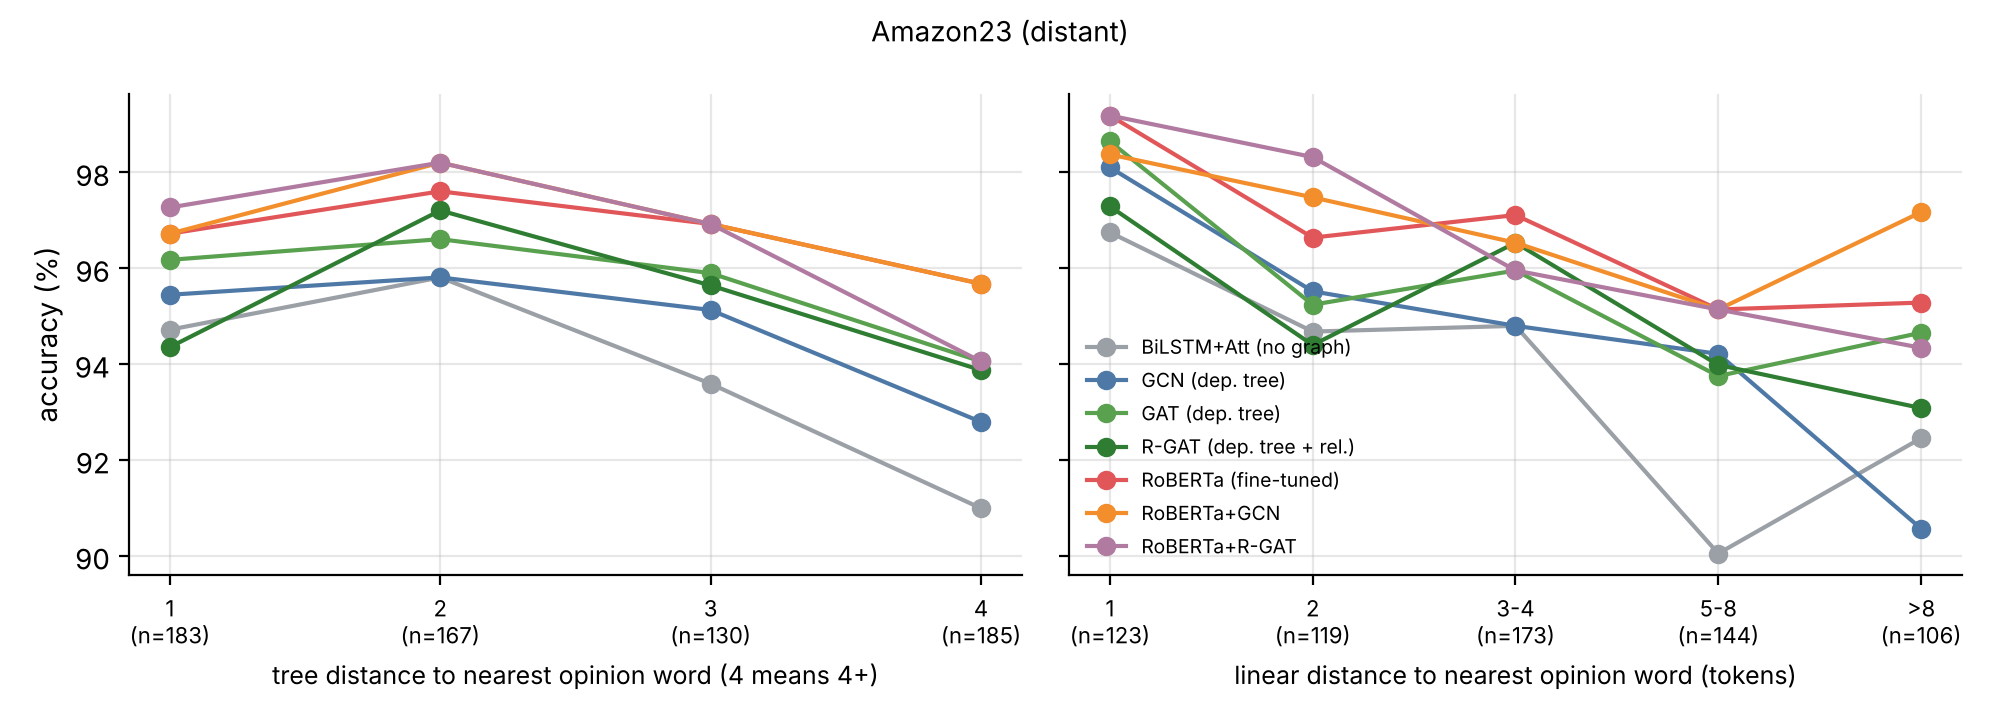

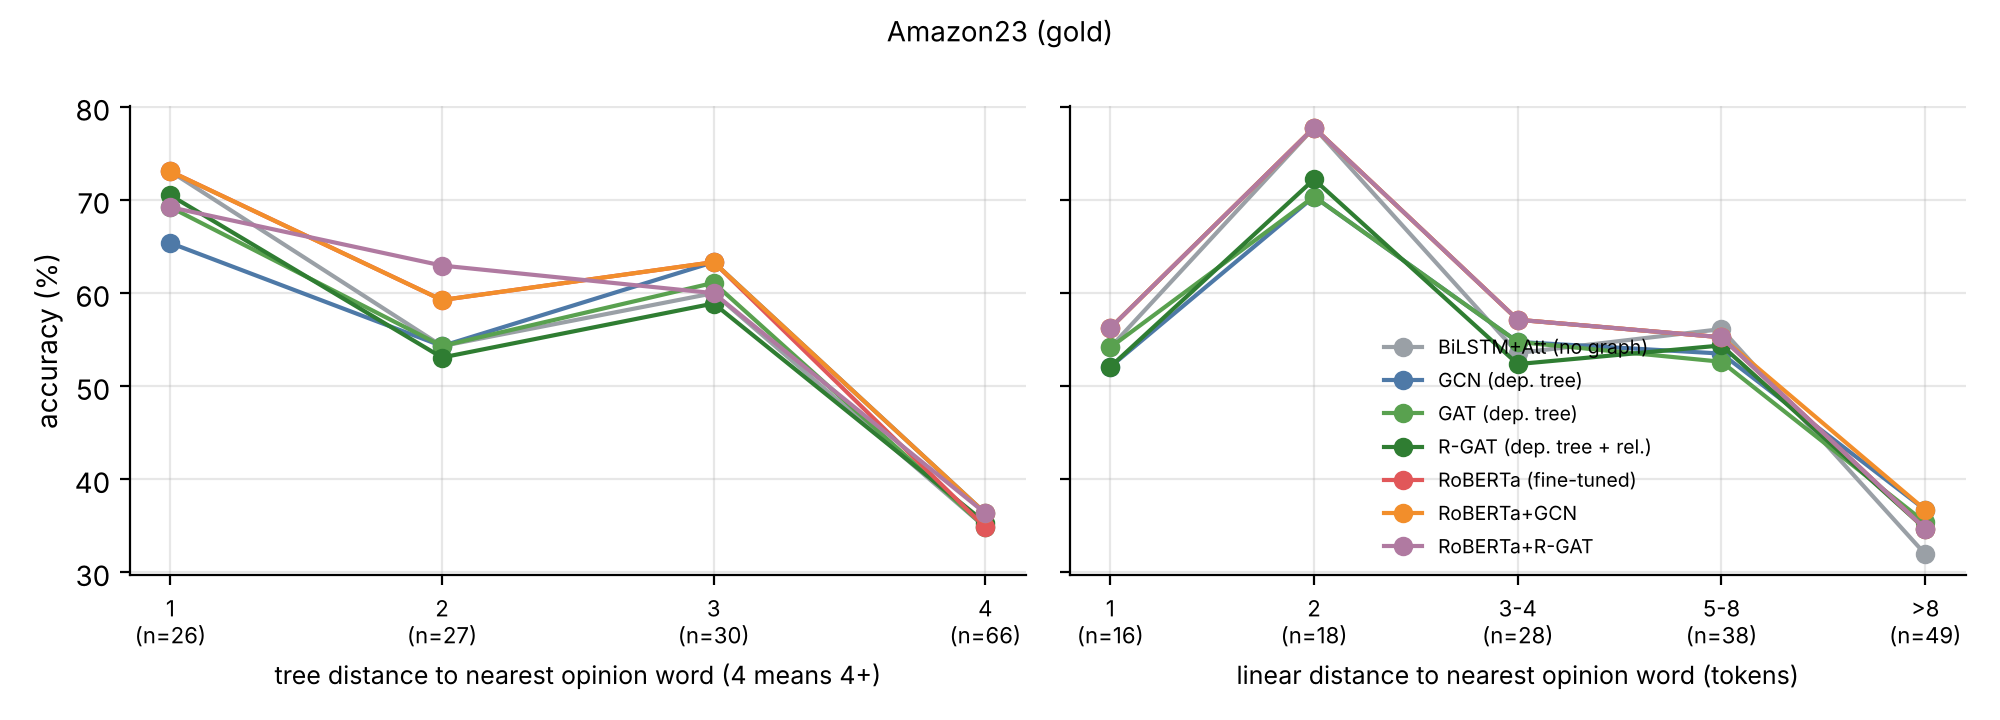

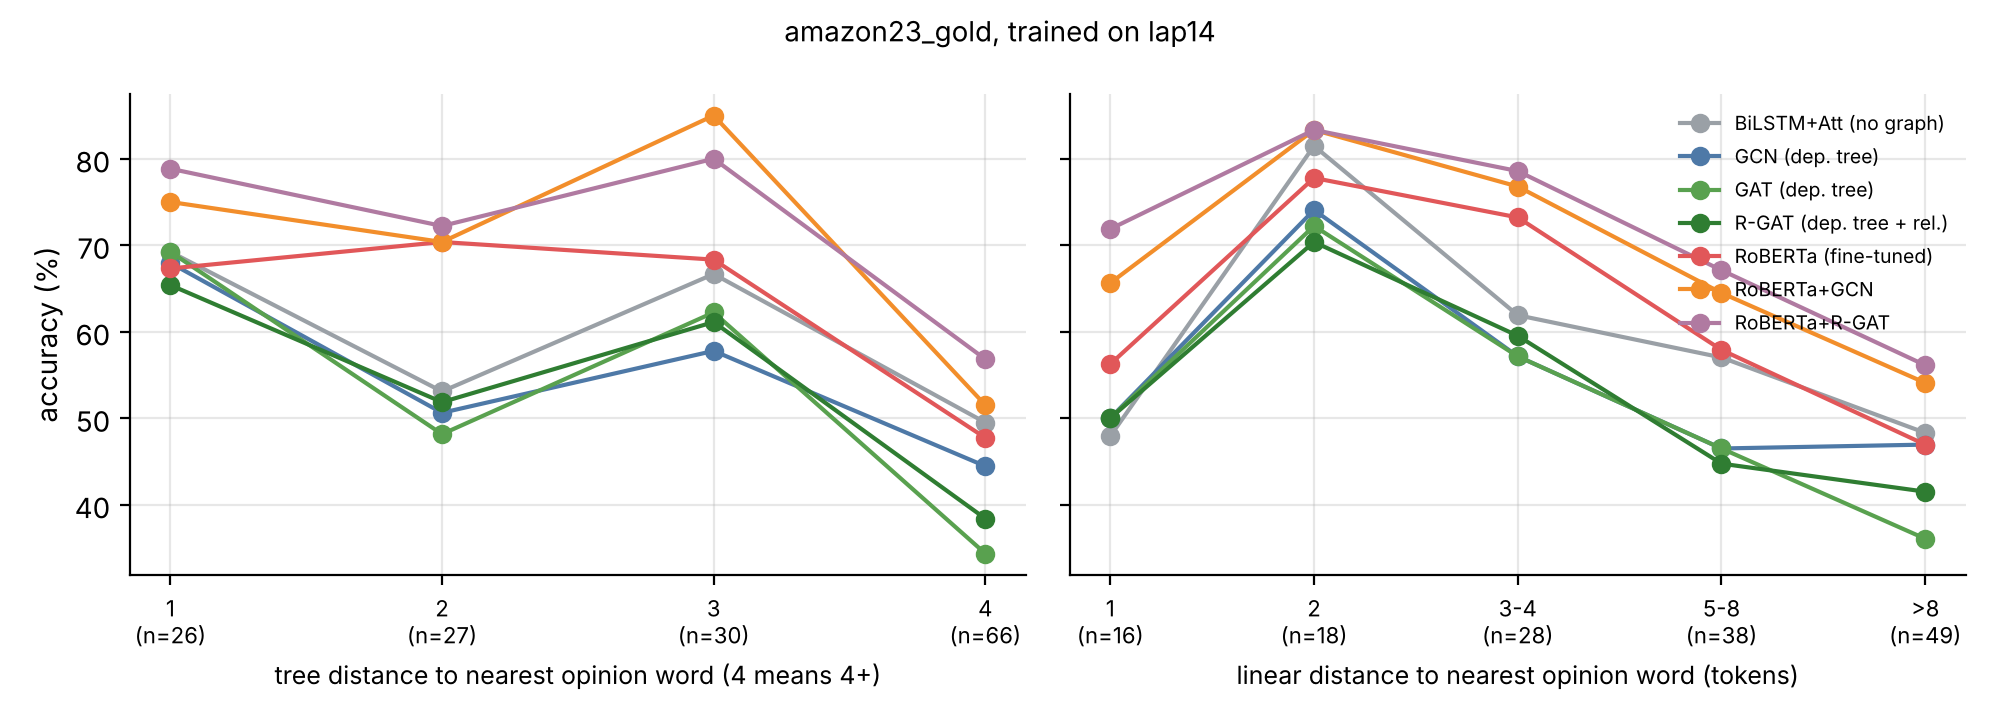

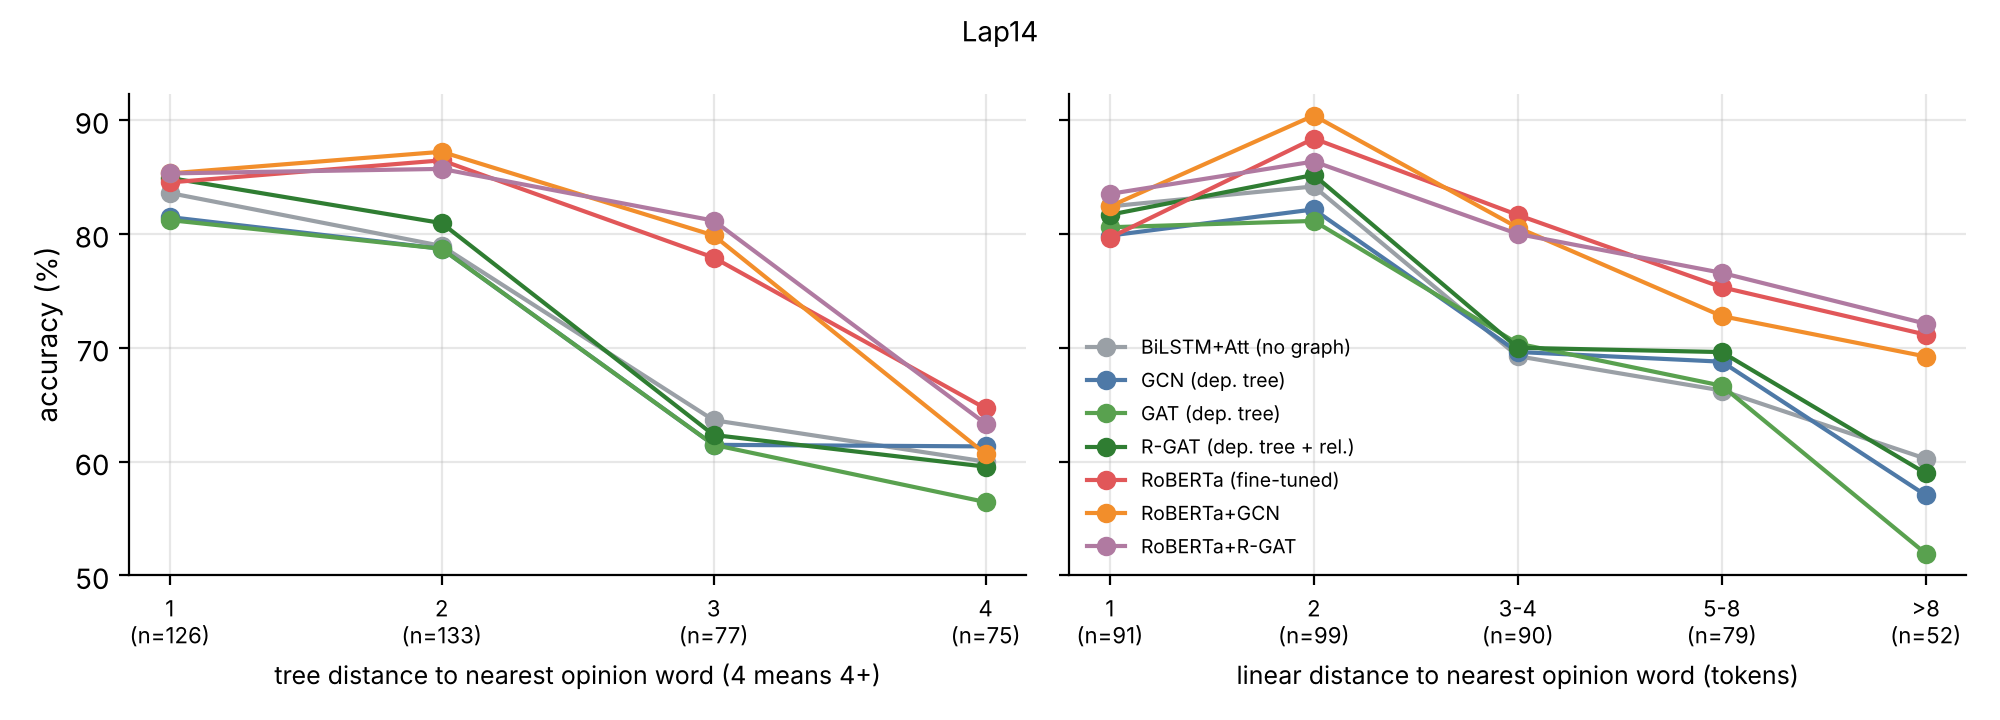

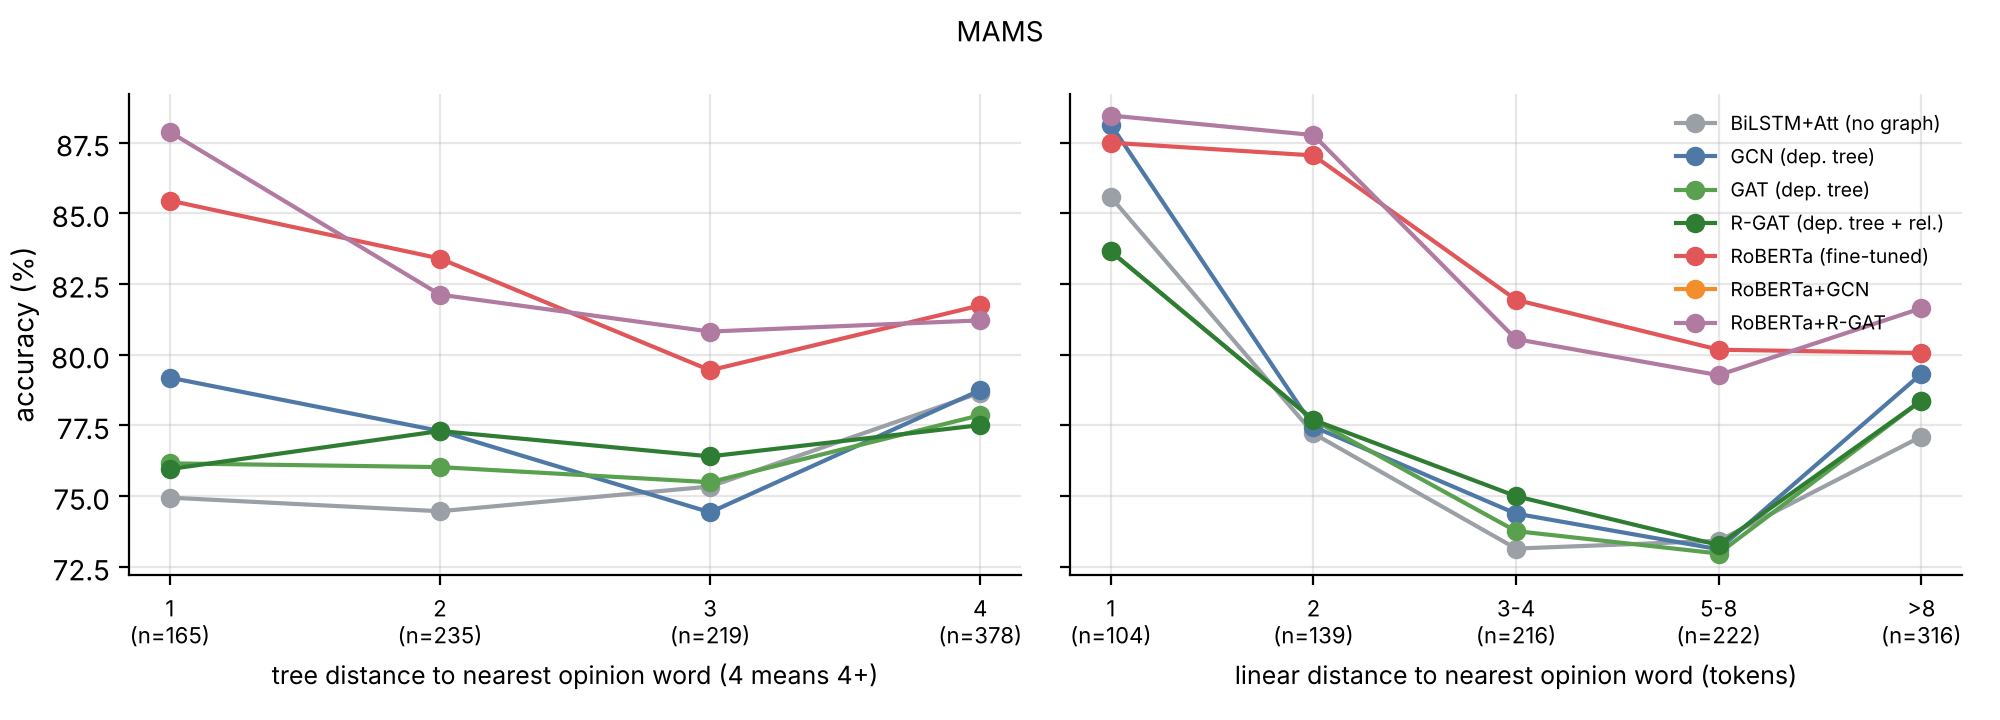

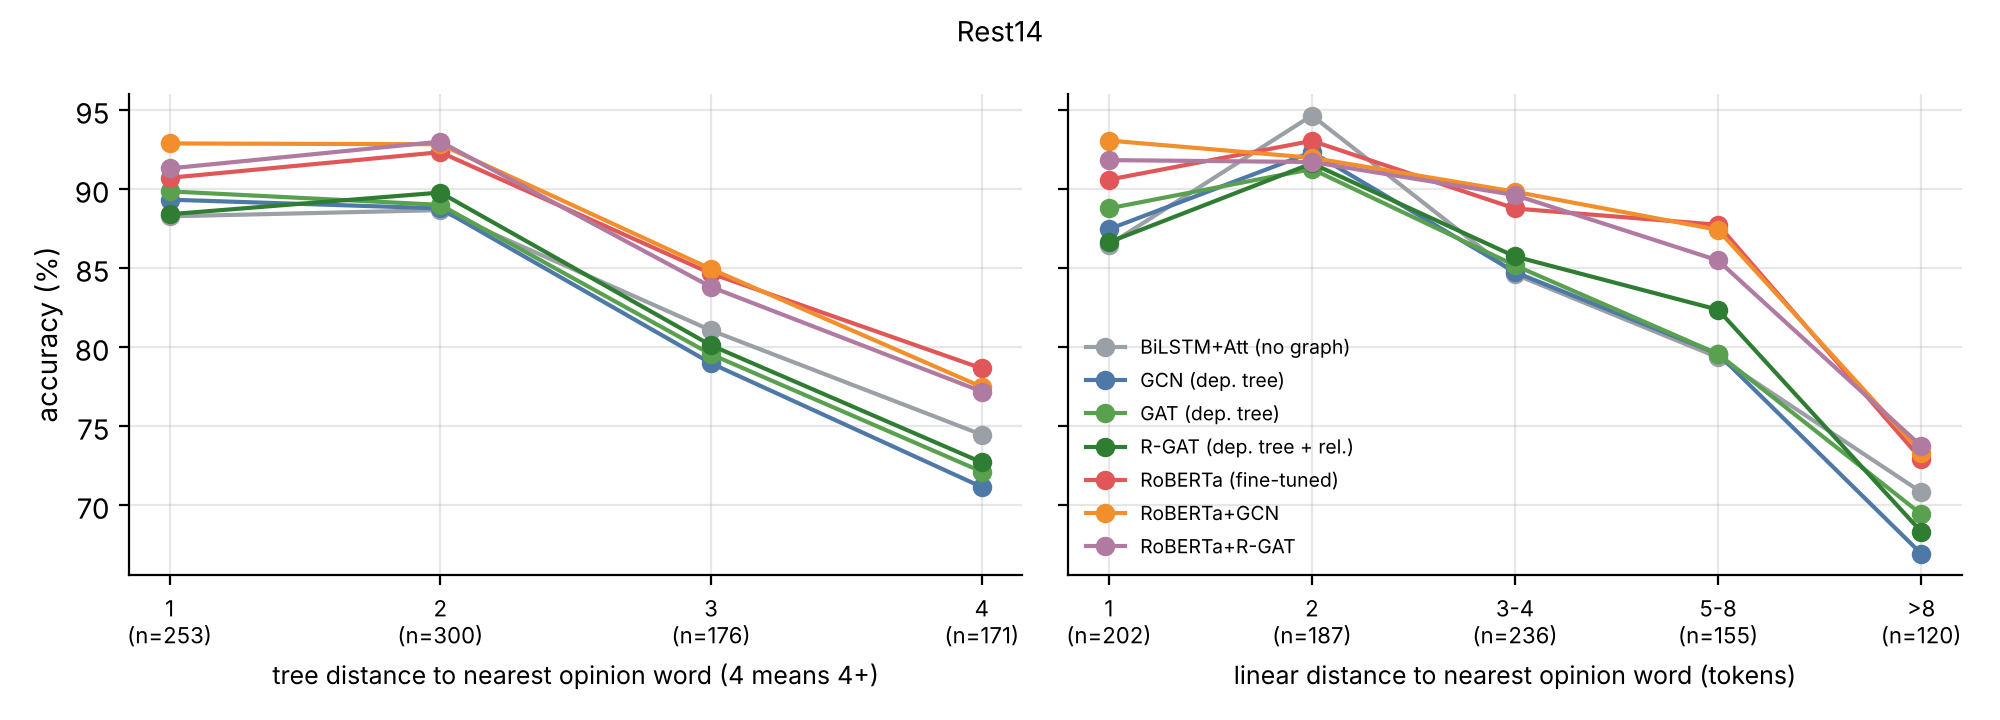

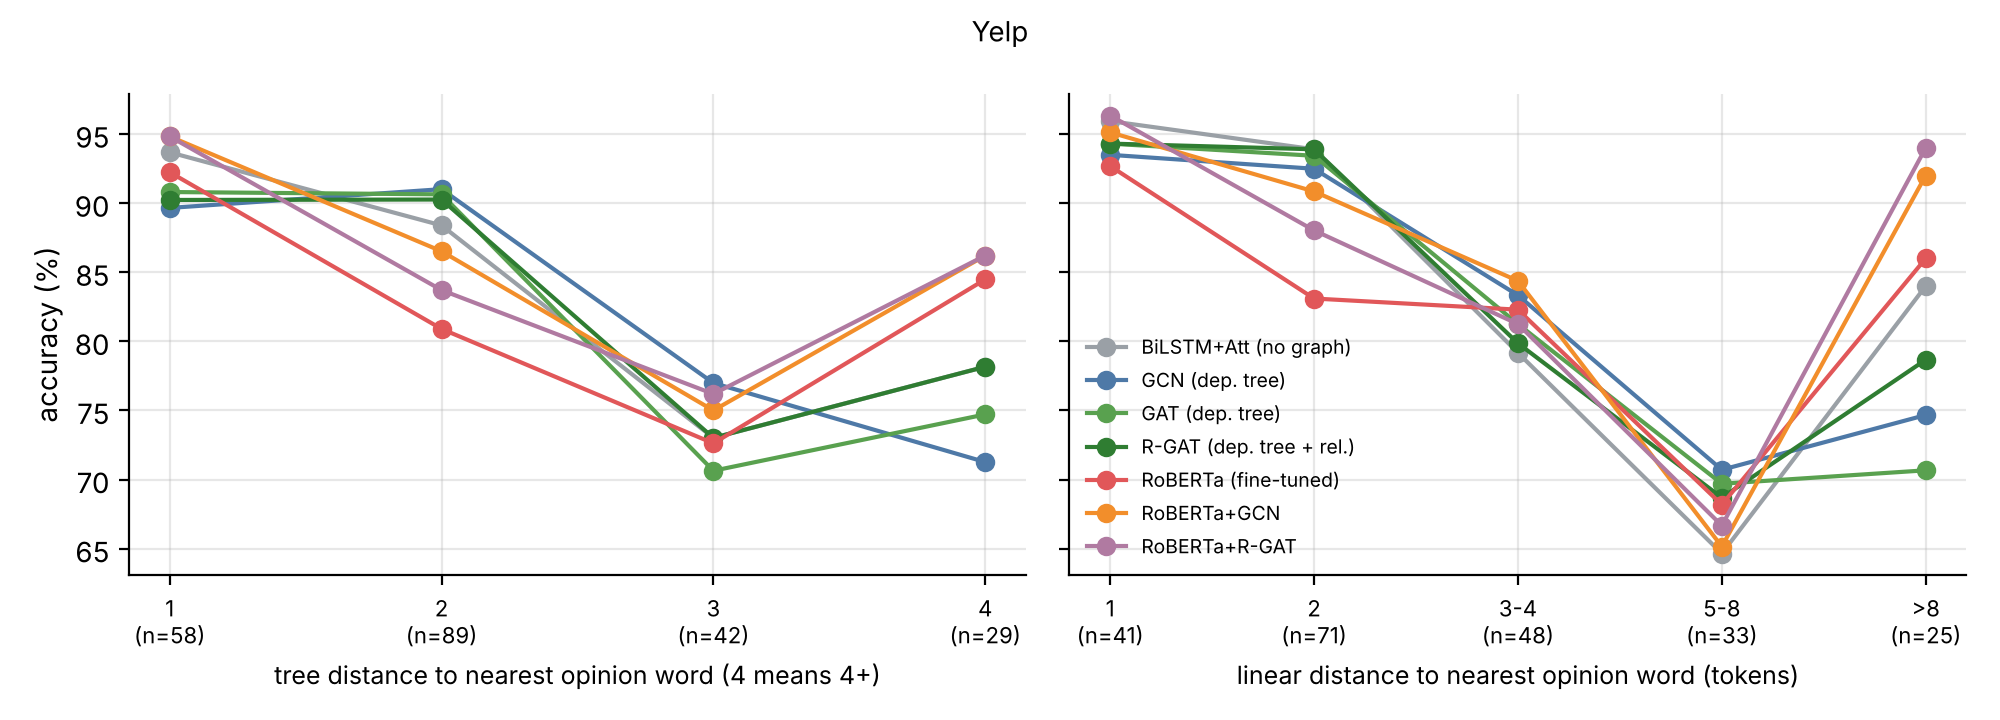

In [11]:
for f in sorted(glob.glob(f'{ROOT}/results/figures/distance_*.png')): display(Image(f))

## 7. Efficiency (CPU)

In [12]:
show_md('results/tables/efficiency.md')

|                          |   trainable params (M) |   avg train time (s, CPU) |   inference (examples/s, CPU) |
|:-------------------------|-----------------------:|--------------------------:|------------------------------:|
| BiLSTM+Att (no graph)    |                    1.5 |                     544.4 |                        1457.5 |
| GCN (dep. tree)          |                    2.2 |                    1192.1 |                         538.6 |
| GAT (dep. tree)          |                    2.2 |                     793.8 |                         670.4 |
| R-GAT (dep. tree + rel.) |                    2.3 |                     890.1 |                         682   |
| RoBERTa (fine-tuned)     |                  124.1 |                    1039   |                          72.8 |
| RoBERTa+GCN              |                  124.6 |                     735.5 |                          73.7 |
| RoBERTa+R-GAT            |                  125   |                    1001.1 |                          71.5 |

## 8. Demo: trained models on new sentences
First the GloVe R-GAT (trained on Lap14 + distant Amazon23) with its aspect-attention weights, then the RoBERTa+GCN hybrid (trained on Lap14).

In [13]:
import torch, argparse
from absa.models import GloveGraphModel
from absa.train import featurise, collate, DEPS
from absa.data import LABELS
ck = f'{ROOT}/results/models/lap14-amazon23_rgat.pt'
if os.path.exists(ck):
    ckpt = torch.load(ck, weights_only=False); a = argparse.Namespace(**ckpt['args'])
    model = GloveGraphModel(ckpt['emb'], len(DEPS), kind=a.model, layers=a.layers, heads=a.heads,
                            hidden=a.hidden, dropout=a.dropout, use_pos=not a.no_pos)
    model.load_state_dict(ckpt['state_dict']); model.eval()
    class V:
        stoi = {w: i for i, w in enumerate(ckpt['vocab'])}
        def ids(self, toks): return [self.stoi.get(t.lower(), 1) for t in toks]
    def analyse(sentence, aspect):
        doc = nlp(sentence); i = sentence.lower().index(aspect.lower())
        sp = doc.char_span(i, i + len(aspect), alignment_mode='expand')
        ex = {'tokens': [t.text for t in doc], 'heads': [t.head.i for t in doc], 'deps': [t.dep_ for t in doc],
              'pos': [t.pos_ for t in doc], 'from': sp.start, 'to': sp.end, 'aspect': aspect, 'label': None}
        f = featurise([ex], a, V(), None)
        with torch.no_grad(): p = torch.softmax(model(collate(f, torch.device('cpu'))), -1)[0].numpy()
        att = model.last_attention[0].numpy()
        top = sorted(zip(ex['tokens'], att), key=lambda x: -x[1])[:4]
        print(f'{aspect!r:18s} -> {LABELS[p.argmax()]:8s} {np.round(p, 2)}   attends to: ' + ', '.join(f'{w}({v:.2f})' for w, v in top))
    for s, asps in [('The battery life is great but the screen is too dim for outdoor use.', ['battery life', 'screen']),
                    ('The sound quality is amazing, although the ear cushions get uncomfortable after an hour.', ['sound quality', 'ear cushions']),
                    ('I bought this cable for my laptop and it stopped working after two days.', ['cable', 'laptop']),
                    ('Customer service never answered, but the keyboard itself works fine.', ['Customer service', 'keyboard'])]:
        print(s)
        for asp in asps: analyse(s, asp)
        print()
else:
    print('checkpoint not found; train it with: python -m absa.train --dataset lap14+amazon23 --model rgat --save-model ../results/models/lap14-amazon23_rgat.pt')

The battery life is great but the screen is too dim for outdoor use.
'battery life'     -> positive [0. 0. 1.]   attends to: great(1.00), dim(0.00), outdoor(0.00), life(0.00)
'screen'           -> positive [0. 0. 1.]   attends to: great(1.00), dim(0.00), outdoor(0.00), but(0.00)

The sound quality is amazing, although the ear cushions get uncomfortable after an hour.
'sound quality'    -> positive [0. 0. 1.]   attends to: amazing(0.88), uncomfortable(0.05), sound(0.02), quality(0.01)
'ear cushions'     -> positive [0. 0. 1.]   attends to: amazing(0.99), uncomfortable(0.00), sound(0.00), ,(0.00)

I bought this cable for my laptop and it stopped working after two days.
'cable'            -> negative [0.82 0.18 0.  ]   attends to: stopped(0.97), working(0.01), and(0.01), bought(0.00)
'laptop'           -> negative [0.79 0.21 0.  ]   attends to: stopped(0.96), working(0.02), and(0.01), bought(0.01)

Customer service never answered, but the keyboard itself works fine.
'Customer service' -> 

In [14]:
ck2 = f'{ROOT}/results/models/lap14_roberta-gcn.pt'
if os.path.exists(ck2):
    from transformers import AutoTokenizer
    from absa.models import RobertaABSA
    c2 = torch.load(ck2, weights_only=False); a2 = argparse.Namespace(**c2['args'])
    tok = AutoTokenizer.from_pretrained(a2.plm)
    m2 = RobertaABSA(a2.plm, kind=a2.model, n_rel=len(DEPS), layers=a2.layers, heads=a2.heads)
    m2.load_state_dict(c2['state_dict']); m2.eval()
    def analyse2(sentence, aspect):
        doc = nlp(sentence); i = sentence.lower().index(aspect.lower())
        sp = doc.char_span(i, i + len(aspect), alignment_mode='expand')
        ex = {'tokens': [t.text for t in doc], 'heads': [t.head.i for t in doc], 'deps': [t.dep_ for t in doc],
              'pos': [t.pos_ for t in doc], 'from': sp.start, 'to': sp.end, 'aspect': aspect, 'label': None}
        with torch.no_grad(): p = torch.softmax(m2(collate(featurise([ex], a2, None, tok), torch.device('cpu'))), -1)[0].numpy()
        print(f'{aspect!r:18s} -> {LABELS[p.argmax()]:8s} {np.round(p, 2)}')
    for s, asps in [('The battery life is great but the screen is too dim for outdoor use.', ['battery life', 'screen']),
                    ('The sound quality is amazing, although the ear cushions get uncomfortable after an hour.', ['sound quality', 'ear cushions']),
                    ('I bought this cable for my laptop and it stopped working after two days.', ['cable', 'laptop']),
                    ('Customer service never answered, but the keyboard itself works fine.', ['Customer service', 'keyboard'])]:
        print(s)
        for asp in asps: analyse2(s, asp)
        print()

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

The battery life is great but the screen is too dim for outdoor use.
'battery life'     -> positive [0. 0. 1.]
'screen'           -> negative [1. 0. 0.]

The sound quality is amazing, although the ear cushions get uncomfortable after an hour.
'sound quality'    -> positive [0. 0. 1.]
'ear cushions'     -> negative [0.95 0.02 0.03]

I bought this cable for my laptop and it stopped working after two days.


'cable'            -> neutral  [0.44 0.53 0.02]
'laptop'           -> neutral  [0.11 0.88 0.01]

Customer service never answered, but the keyboard itself works fine.
'Customer service' -> positive [0.01 0.02 0.97]
'keyboard'         -> positive [0. 0. 1.]



## 9. Corpus-scale aspect mining on Amazon Reviews 2023 (100k reviews)

{
 "n_reviews": 97487,
 "n_sentences": 499928,
 "n_mentions": 588417,
 "n_distinct_aspects": 600,
 "timing": {
  "parse_s": 153.69331240653992,
  "featurise_s": 16.16924548149109,
  "inference_s": 266.5659017562866,
  "mentions_per_s_inference": 2207.3978559267207,
  "reviews_per_s_end_to_end": 223.37452529894676
 },
 "pred_distribution": {
  "positive": 0.5057,
  "negative": 0.273,
  "neutral": 0.2213
 },
 "avg_star_by_predicted_polarity": {
  "negative": 3.759,
  "neutral": 4.106,
  "positive": 4.442
 },
 "spearman_review_aspect_sentiment_vs_stars": {
  "rho": 0.4116,
  "p": 0.0,
  "n_reviews": 80558
 }
}


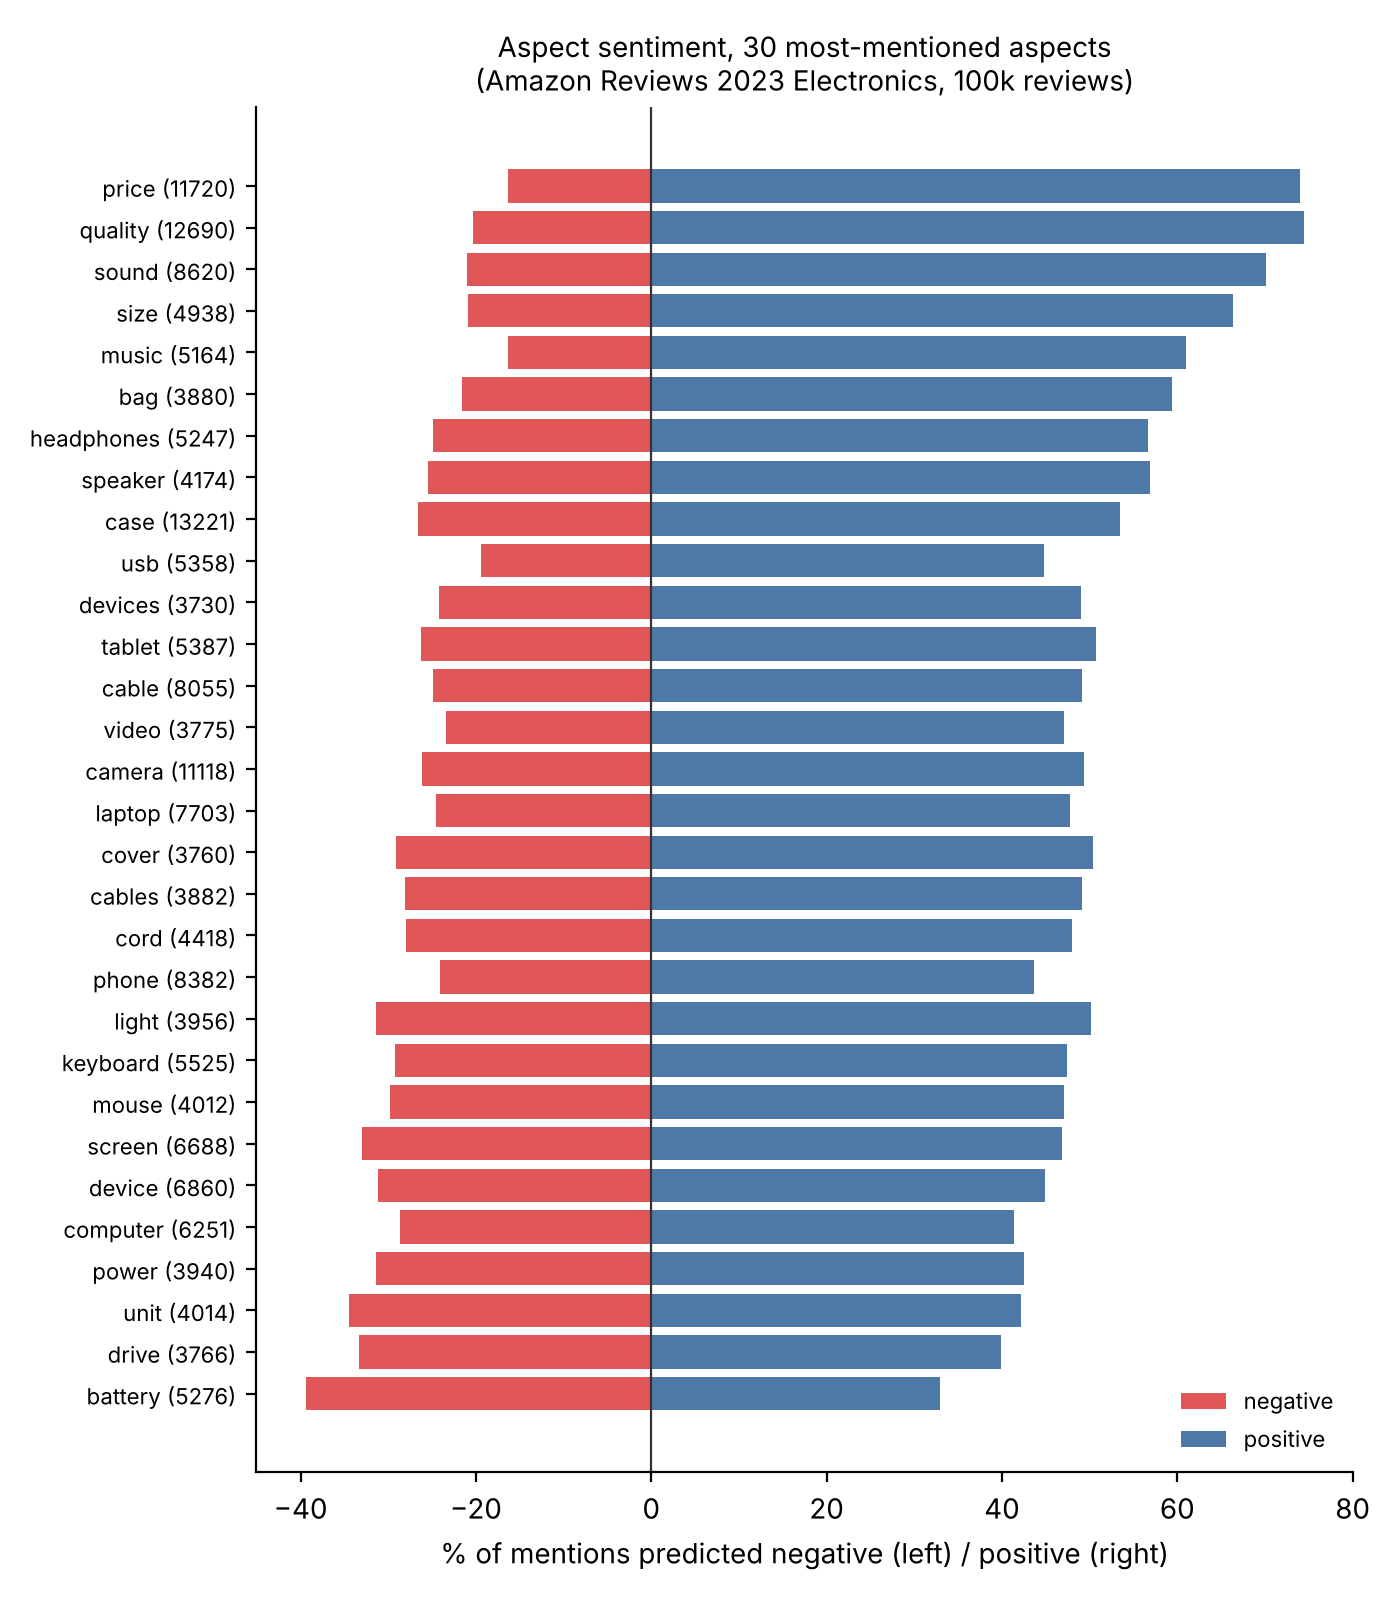

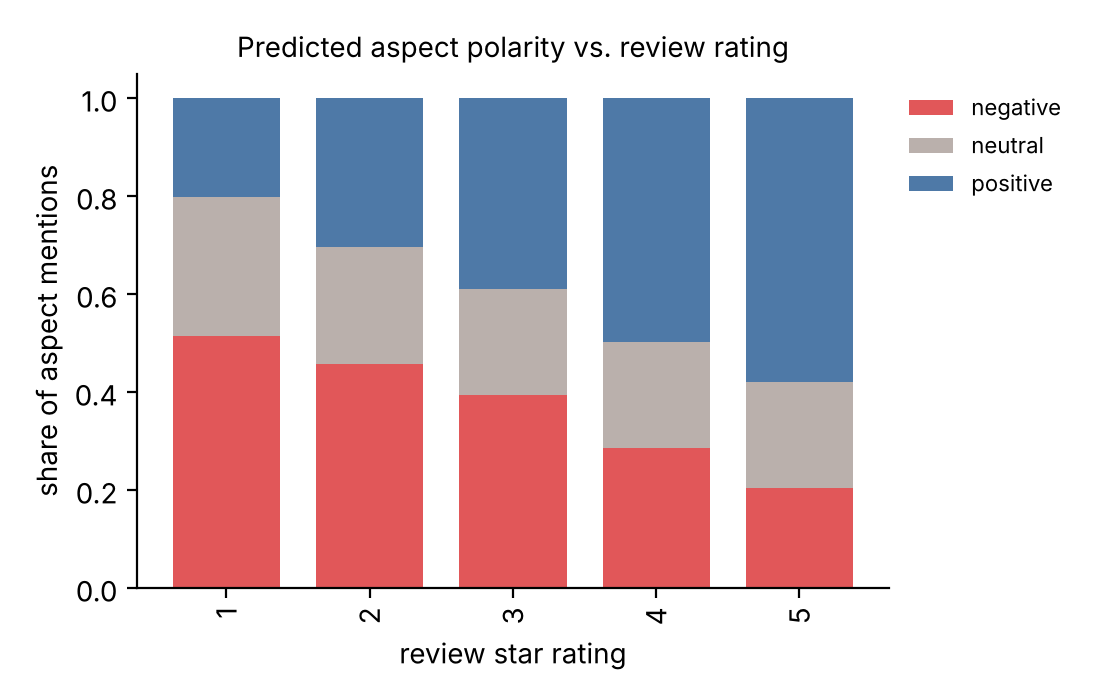

,aspect,mentions,pos,neg,neu,avg_rating,net_sentiment
0,case,13221,0.5346,0.2661,0.1993,4.1933,0.2685
1,quality,12690,0.7440,0.2028,0.0532,4.2940,0.5411
2,price,11720,0.7398,0.1633,0.0969,4.4020,0.5765
3,camera,11118,0.4934,0.2609,0.2456,4.1147,0.2325
4,sound,8620,0.7009,0.2099,0.0892,4.2159,0.4911
5,phone,8382,0.4363,0.2414,0.3224,4.1094,0.1949
6,cable,8055,0.4908,0.2494,0.2598,4.3322,0.2413
7,laptop,7703,0.4775,0.2455,0.2770,4.3088,0.2320
8,device,6860,0.4485,0.3120,0.2395,3.9761,0.1366
9,screen,6688,0.4685,0.3303,0.2013,4.0668,0.1382


In [15]:
p = f'{ROOT}/results/amazon_mining/summary.json'
if os.path.exists(p):
    print(json.dumps(json.load(open(p)), indent=1))
    display(Image(f'{ROOT}/results/amazon_mining/top_aspects.png')); display(Image(f'{ROOT}/results/amazon_mining/polarity_by_star.png'))
    display(pd.read_csv(f'{ROOT}/results/amazon_mining/aspect_summary.csv').head(25))

### Accuracy vs. throughput at corpus scale
The same pipeline with the RoBERTa+GCN hybrid on the first 10k reviews: about 28x slower on CPU, but far more accurate on the gold set (about 64 % vs 49 %). Agreement between the two models on identical mentions is reported below.

In [16]:
p = f'{ROOT}/results/amazon_mining_roberta_gcn_10k/summary.json'
if os.path.exists(p):
    r = json.load(open(p)); g = json.load(open(f'{ROOT}/results/amazon_mining/summary.json'))
    display(pd.DataFrame({'GloVe R-GAT (100k reviews)': [g['n_mentions'], round(g['timing']['mentions_per_s_inference']), round(g['timing']['reviews_per_s_end_to_end'], 1), g['spearman_review_aspect_sentiment_vs_stars']['rho']],
                          'RoBERTa+GCN (10k reviews)': [r['n_mentions'], round(r['timing']['mentions_per_s_inference']), round(r['timing']['reviews_per_s_end_to_end'], 1), r['spearman_review_aspect_sentiment_vs_stars']['rho']]},
                         index=['aspect mentions', 'mentions/s (inference)', 'reviews/s end-to-end', 'Spearman(aspect sentiment, stars)']))
    print('agreement of the two models on the same 10k reviews:', r.get('agreement_with_other_model'))

,GloVe R-GAT (100k reviews),RoBERTa+GCN (10k reviews)
aspect mentions,588417.0000,65432.0000
mentions/s (inference),2207.0000,77.0000
reviews/s end-to-end,223.4000,11.2000
"Spearman(aspect sentiment, stars)",0.4116,0.4816


agreement of the two models on the same 10k reviews: 0.6182
